## Experimenting with placing priors on GP nodes from plausible $n(z)$ realizations

### 1. Preparing, plotting, and reconstructing $n(z)$ using GP

In [1]:
# Necessary imports #

# General #

import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy import integrate
from scipy.stats import gaussian_kde
from copy import deepcopy
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF, Matern, RationalQuadratic, ExpSineSquared,
    DotProduct, ConstantKernel as C
)
import sys
import os

import euclidlib as el
import seaborn as sns

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(repo_root)

# Gaussian processes

import matplotlib.pyplot as plt

from binz.run_gp import build_gp_nz 

import matplotlib as mpl 
mpl.rcParams['font.family'] = "serif"
mpl.rcParams['font.serif'] = "Times New Roman"
mpl.rcParams['text.usetex'] = True

In [107]:
# Import and prepare original n(z) distribution #

zs = np.linspace(1e-4, 3, 100)
z, nz = el.phz.redshift_distributions('/home/jipdebuck/nzTabSPV3.fits')

def normalize_dndz(nz_example, z_nz):
    normalized = {}
    for key in nz_example:
        normalized[key] = nz_example[key] / integrate.trapezoid(nz_example[key], z_nz)
    return normalized

# Normalize both dndz_pos and dndz_she
dndz_pos_norm = normalize_dndz(nz, z)
dndz_she_norm = normalize_dndz(nz, z)

# Function to resample the normalized dndz
def resample_dndz(nz_example, z_nz, myz):
    my_dndz = np.vstack(list(nz_example.values())) #stacking arrays vertically
    my_dndz_norm = np.zeros([len(nz_example), len(myz)]) #creating an empty array
    for i in range(len(nz_example)):
        my_dndz_norm[i, :] = np.interp(myz, z_nz, my_dndz[i, :]) #interpolating to new myz values
    return my_dndz_norm

# Resampling the normalized dndz with 100 values
my_dndz_pos_norm = resample_dndz(dndz_pos_norm, z, zs)
my_dndz_she_norm = resample_dndz(dndz_she_norm, z, zs)

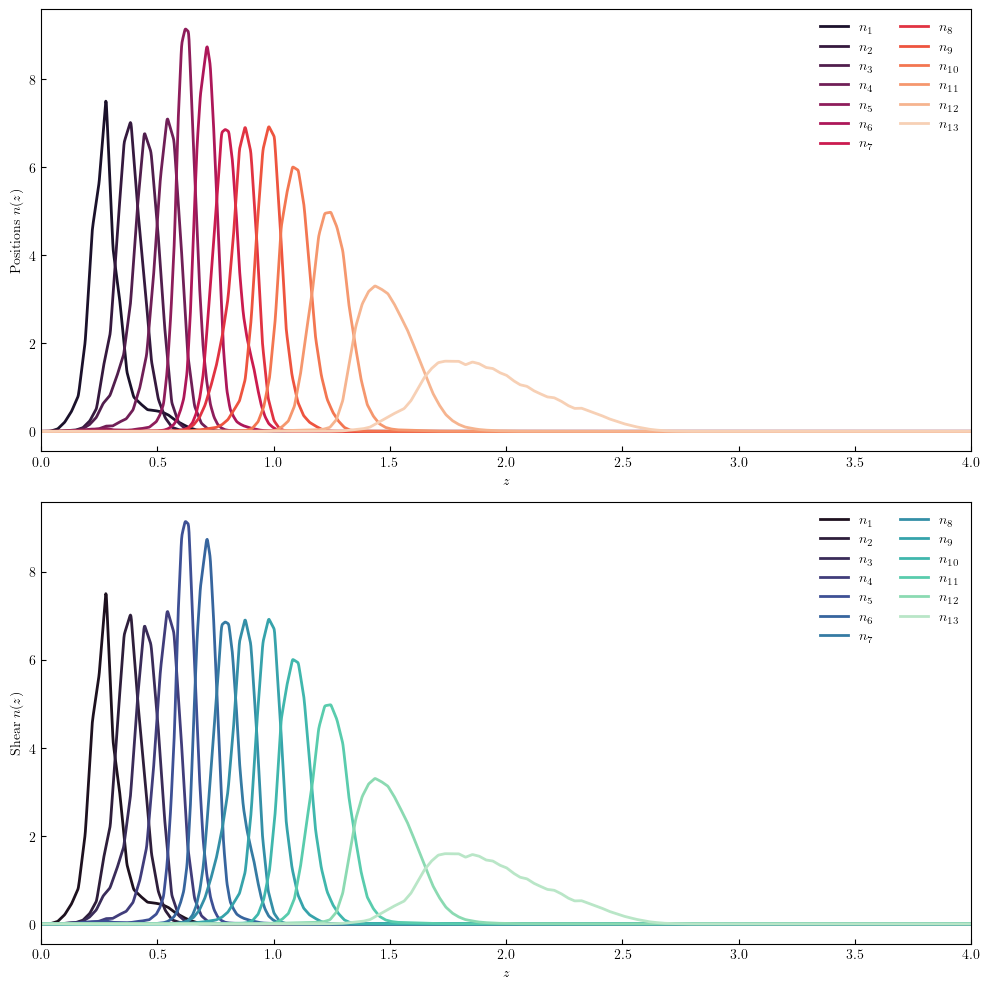

In [3]:
# Plotting of original n(z) distributions #

fig, axs = plt.subplots(2, 1, figsize=(10, 10))

# Customize tick parameters for both axes
for ax in axs.flatten():
    ax.tick_params(axis='both', which='both', direction='in')

# Plot positions n(z)
for i, (key, color) in enumerate(zip(dndz_pos_norm.keys(), sns.color_palette("rocket", len(dndz_pos_norm)))):
    axs[0].plot(z, dndz_pos_norm[key], label=f'$n_{{{i+1}}}$', linewidth=2, color=color)

# Plot shear n(z)
for j, (key, color) in enumerate(zip(dndz_she_norm.keys(), sns.color_palette("mako", len(dndz_she_norm)))):
    axs[1].plot(z, dndz_she_norm[key], label=f'$n_{{{j+1}}}$', linewidth=2, color=color)

# Set labels and legends
axs[0].set_xlabel(r'$z$')
axs[0].set_ylabel(r'Positions $n(z)$')
axs[0].set_xlim(0, 4)
axs[0].legend(frameon=False, ncol=2)

axs[1].set_xlabel(r'$z$')
axs[1].set_ylabel(r'Shear $n(z)$')
axs[1].set_xlim(0, 4)
axs[1].legend(frameon=False, ncol=2)

plt.tight_layout()
plt.show()

In [45]:
# Define parameters for GP reconstruction #

z_meds = []   # positions of median redshift for each bin
n_meds = []   # height of n(z) at median redshift for each bin

for key, nz in dndz_she_norm.items():
    # --- CDF & median node ---
    cdf = integrate.cumulative_trapezoid(nz, z, initial=0)
    cdf /= cdf[-1]
    z_med = np.interp(0.5, cdf, z)
    n_med = nz[np.argmin(np.abs(z - z_med))]
    z_meds.append(z_med)
    n_meds.append(n_med)

corr_len = 0.03                                # correlation length for the GP kernel
z_bounds = (0,3)                              # bounds for the redshift
z_pred = np.linspace(0, 3, 400)       # prediction points for GP
alpha = 1e-8                                  # noise level during fitting 
kernel_class = RBF
nu = 1.5                                      # necessary for Matern only, defines smoothness 
const_value = 0.04                            # amplitude of constant kernel
const_bounds = (1e-4, 1.0)                    # bounds for constant kernel amplitude

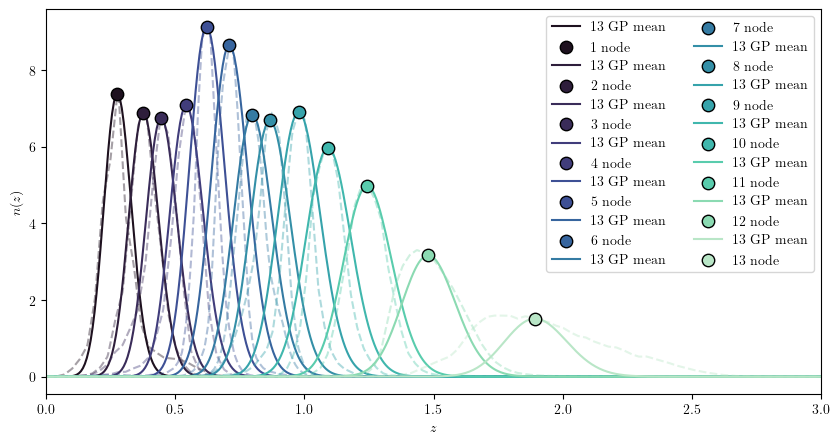

In [5]:
# GP reconstruction and plotting of results #

# Perform GP reconstruction #
priors, predictions = build_gp_nz(n_meds, z_meds, corr_len, z_bounds, z_pred, alpha, kernel_class, nu, const_value, const_bounds)

# Plot GP reconstruction results #
palette = sns.color_palette("mako", 13)
fig, ax = plt.subplots(figsize=(10, 5))

for j, nz in enumerate(n_meds):
    y_pred, y_std = predictions[j]
    X_train, y_train = z_meds[j], n_meds[j]

    ax.plot(z_pred, y_pred, color=palette[j], label=f"{key} GP mean")
    #ax.fill_between(z_pred.ravel(), (y_pred - y_std).ravel(), (y_pred + y_std).ravel(),
    #                color=palette[j], alpha=0.2)

    ax.plot(z, dndz_she_norm[j+1], '--', color=palette[j], alpha=0.4)
    ax.scatter(X_train, y_train, color=palette[j], edgecolor='black', s=80, zorder=3, label=f"{j+1} node")

ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$n(z)$")
ax.set_xlim(0, 3)
ax.legend(loc="upper right", ncol=2)
plt.show()


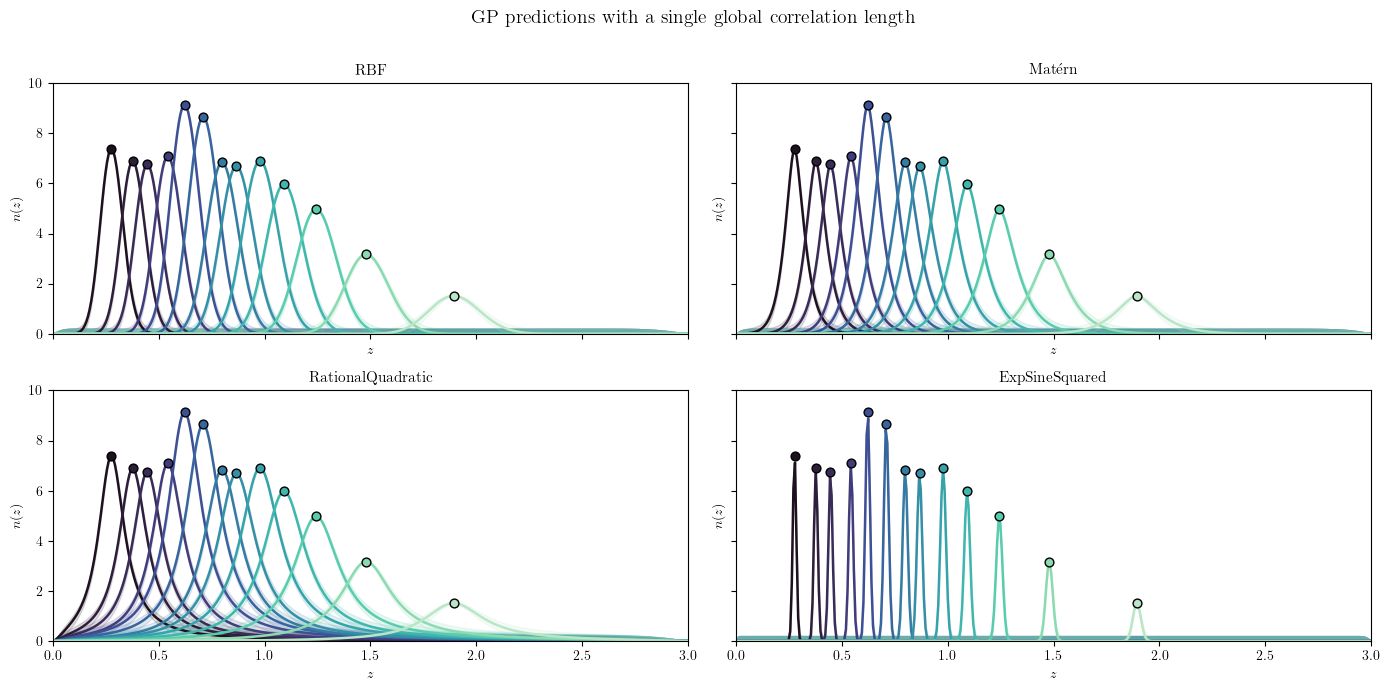

In [6]:
# Results using different kernels #

# Define different kernels #
kernel_dict = {
    "RBF": RBF,
    "Matérn": Matern,
    "RationalQuadratic": RationalQuadratic,
    "ExpSineSquared": ExpSineSquared
}

# Initialize figure for plotting #
n_kernels = len(kernel_dict)
palette = sns.color_palette("mako", len(dndz_she_norm))

fig, axs = plt.subplots(nrows=int(np.ceil(n_kernels/2)), ncols=2,
                        figsize=(14, 3.5 * int(np.ceil(n_kernels/2))),
                        sharex=True, sharey=True)
axs = axs.flatten()

# Compute and plot GP predictions for each kernel #
for ax, (kname, kernel) in zip(axs, kernel_dict.items()):
    
    z_meds = []
    n_meds = []
    for j, (key, nz) in enumerate(dndz_she_norm.items()):
        # --- Compute CDF and median node ---
        cdf = integrate.cumulative_trapezoid(nz, z, initial=0)
        cdf /= cdf[-1]
        z_med = np.interp(0.5, cdf, z)
        n_med = nz[np.argmin(np.abs(z - z_med))]
        z_meds.append(z_med)
        n_meds.append(n_med)

    
    gp_prior, gp_pred = build_gp_nz(n_meds, z_meds, corr_len, z_bounds, z_pred, alpha, kernel, nu, const_value, const_bounds)

    for j, nz in enumerate(n_meds):
        y_pred, y_std = gp_pred[j]
        ax.plot(z_pred, y_pred, color=palette[j], label=f"{key} mean", lw=1.8)
        ax.fill_between(z_pred.ravel(), (y_pred - y_std).ravel(),
                        (y_pred + y_std).ravel(), color=palette[j], alpha=0.15)
        ax.scatter(z_meds[j], nz, color=palette[j], edgecolor='black', s=40, zorder=3)

        ax.set_title(kname, fontsize=11)
        ax.set_xlim(0, 3)
        ax.set_ylim(0,10)
        ax.set_xlabel(r"$z$")
        ax.set_ylabel(r"$n(z)$")

for ax in axs[len(kernel_dict):]:
    ax.axis("off")

fig.suptitle("GP predictions with a single global correlation length", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


### 2. Guada's work: GP informed by a training node sampled from a prior that is a mean of all possible realiations

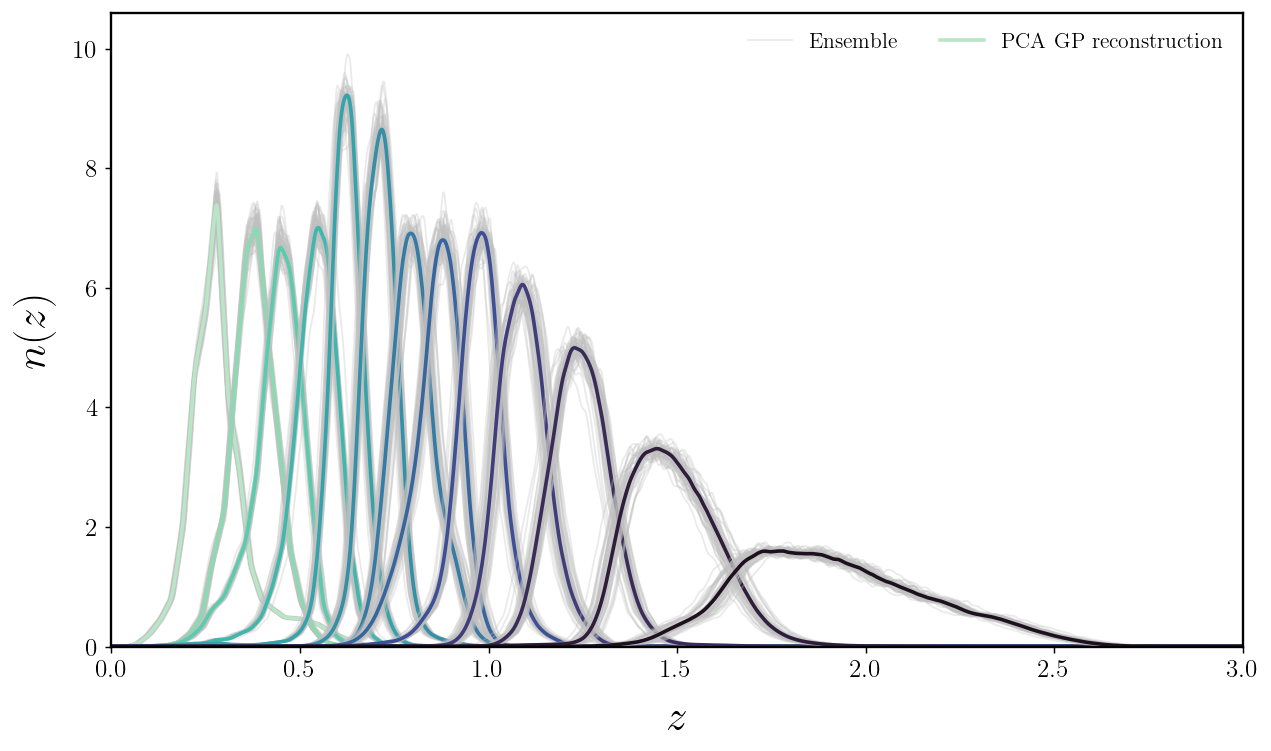

[1.00000000e-03 2.99966667e-03 4.99933333e-03 ... 5.99600067e+00
 5.99800033e+00 6.00000000e+00]


In [7]:
# Define the n(z) ensemble and redshift grid to evaluate on 

import numpy as np
from sklearn.decomposition import PCA


def build_pca_nz_prior(z_grid, nz_ensemble, n_components=5, log_eps=1e-12):
    """
    Build a PCA-based Gaussian prior for n(z) from an ensemble of plausible
    redshift distributions.

    Parameters
    ----------
    z_grid : (N_z,) array
        Redshift grid where all n(z) are evaluated.
    nz_ensemble : (N_ens, N_z) array
        Ensemble of plausible n(z) curves.
    n_components : int, optional
        Number of PCA modes to keep (default: 5).
    log_eps : float, optional
        Small number added inside the log to avoid -inf (default: 1e-12).

    Returns
    -------
    prior : dict
        Dictionary containing everything needed to work with the PCA prior:
        - 'z_grid'        : the redshift grid
        - 'pca'           : trained sklearn.decomposition.PCA object
        - 'coeff_mean'    : (k,) mean of PCA coefficients
        - 'coeff_cov'     : (k,k) covariance of PCA coefficients
        - 'n_components'  : number of retained components
        - 'log_eps'       : epsilon used in the log-transform
    """

    z_grid = np.asarray(z_grid)
    nz_ensemble = np.asarray(nz_ensemble)

    # Normalise each n(z) in the ensemble
    norms = np.trapezoid(nz_ensemble, z_grid, axis=1)
    nz_normed = nz_ensemble / norms[:, None]

    # Log-transform to enforce positivity in reconstruction
    f_ensemble = np.log(nz_normed + log_eps)

    # PCA in function space (each f(z) is a row)
    pca = PCA(n_components=n_components)
    coeffs = pca.fit_transform(f_ensemble)   # shape: (N_ens, k)

    # Empirical Gaussian prior on the PCA coefficients
    coeff_mean = np.mean(coeffs, axis=0)               # (k,)
    coeff_cov = np.cov(coeffs, rowvar=False)           # (k, k)

    prior = {
        "z_grid": z_grid,
        "pca": pca,
        "coeff_mean": coeff_mean,
        "coeff_cov": coeff_cov,
        "n_components": n_components,
        "log_eps": log_eps,
    }

    return prior


def sample_coeffs_from_prior(prior, n_samples=1, random_state=None):
    """
    Draw PCA coefficients from the Gaussian prior defined by the ensemble.

    Parameters
    ----------
    prior : dict
        Output of build_pca_nz_prior.
    n_samples : int, optional
        Number of coefficient vectors to sample (default: 1).
    random_state : int or np.random.Generator, optional
        Seed or RNG for reproducibility.

    Returns
    -------
    coeffs : (n_samples, k) array
        Sampled PCA coefficients.
    """
    mean = prior["coeff_mean"]
    cov = prior["coeff_cov"]

    if isinstance(random_state, np.random.Generator):
        rng = random_state
    else:
        rng = np.random.default_rng(random_state)

    coeffs = rng.multivariate_normal(mean, cov, size=n_samples)
    return coeffs


def reconstruct_nz_from_coeffs(prior, coeffs):
    """
    Reconstruct n(z) from PCA coefficients.

    Parameters
    ----------
    prior : dict
        Output of build_pca_nz_prior.
    coeffs : (k,) or (N, k) array
        PCA coefficients.

    Returns
    -------
    nz : (N_z,) or (N, N_z) array
        Reconstructed, normalised n(z) curves.
    """
    pca = prior["pca"]
    z_grid = prior["z_grid"]
    log_eps = prior["log_eps"]

    coeffs = np.atleast_2d(coeffs)  # (N, k)

    # Inverse PCA: back to f(z) = log n(z)
    f_rec = pca.inverse_transform(coeffs)  # (N, N_z)

    # Undo log-transform and renormalise each curve
    nz = np.exp(f_rec) - log_eps
    nz = np.clip(nz, 0.0, None)

    norms = np.trapezoid(nz, z_grid, axis=1)
    nz /= norms[:, None]

    # If input was 1D coefficients, return 1D n(z)
    if coeffs.shape[0] == 1:
        return nz[0]
    return nz


def best_fit_nz_from_prior(prior):
    """
    Convenience helper: return the 'best-fit' n(z) corresponding to the
    mean PCA coefficients (i.e. the ensemble mean in coefficient space).

    Parameters
    ----------
    prior : dict
        Output of build_pca_nz_prior.

    Returns
    -------
    nz_best : (N_z,) array
        Reconstructed n(z) from mean coefficients.
    """
    coeff_mean = prior["coeff_mean"]
    return reconstruct_nz_from_coeffs(prior, coeff_mean)

import numpy as np
from scipy.ndimage import gaussian_filter1d

def generate_bin1_ensemble(
    N_ens=5,
    z_lo=0.001,
    z_hi=6,
    N_z=3001,
    mean_shift_sigma=0.01,
    width_shift_sigma=0.02,
    shape_noise_sigma=0.07,
    smooth_scale=3,
    nz = dndz_she_norm[1]
):
    """
    Generate an ensemble of n(z) realisations for the FIRST bin only:
        z ∈ [0.001, 0.42]
    using small shifts + smooth perturbations.
    """

    # ---------------------------
    # 1. Grid + base bin n(z)
    # ---------------------------
    z = np.linspace(z_lo, z_hi, N_z)
    nz /= np.trapezoid(nz, z)        # ensure norm within [0, 3] part
    nz_bin = nz.copy()               # for first bin, that's it

    # ---------------------------
    # Build ensemble
    # ---------------------------
    ensemble = []

    z_mean = np.trapezoid(z * nz_bin, z)

    for _ in range(N_ens):

        # Mean shift
        dz = np.random.normal(0, mean_shift_sigma) * z_mean
        z_shift = np.clip(z + dz, z_lo, z_hi)

        # Width/stretch shift
        width = 1 + np.random.normal(0, width_shift_sigma)
        z_stretch = z_mean + width * (z_shift - z_mean)
        z_stretch = np.clip(z_stretch, z_lo, z_hi)

        # Smooth random shape fluctuation
        noise = np.random.normal(0, shape_noise_sigma, N_z)
        noise_smooth = gaussian_filter1d(noise, smooth_scale)
        nz_pert = nz_bin * (1 + noise_smooth)
        nz_pert = np.clip(nz_pert, 1e-12, None)

        # Interpolate to shifted grid
        nz_new = np.interp(z, z_stretch, nz_pert, left=0, right=0)

        # Normalise inside the bin
        nz_new /= np.trapezoid(nz_new, z)

        ensemble.append(nz_new)

    return z, np.array(ensemble)

z_ens_list, nz_ensemble_list = zip(*[
    generate_bin1_ensemble(
        N_ens=50, 
        nz=dndz_she_norm[i], 
        N_z=3001
    )
    for i in range(1, 14)
])

nz_means, nz_samples_list = zip(*[
    (
        best_fit_nz_from_prior( prior := build_pca_nz_prior(
            z_grid := generate_bin1_ensemble(
                N_ens=50,
                nz=dndz_she_norm[i],
                N_z=3001
            )[0],
            nz_ensemble := generate_bin1_ensemble(
                N_ens=50,
                nz=dndz_she_norm[i],
                N_z=3001
            )[1],
            n_components=5
        )),
        reconstruct_nz_from_coeffs(
            prior,
            sample_coeffs_from_prior(prior, n_samples=20, random_state=42)
        )
    )
    for i in range(1, 14)
])

import matplotlib.pyplot as plt
import seaborn as sns

def plot_gp_means_and_ensembles(z_list, nz_ens_list, nz_mean_list, dndz_she_norm):
    """
    Plot ensemble curves and PCA–GP mean curves for bins 1 → 14,
    each in the color corresponding to its key in dndz_she_norm.

    Parameters
    ----------
    z_list : list of arrays
        List of z-grids, one per bin.
    nz_ens_list : list of arrays
        Each element is (N_ens, N_z) ensemble for that bin.
    nz_mean_list : list of arrays
        PCA-GP mean n(z) curves for each bin.
    dndz_she_norm : dict
        Dict whose keys define bin order and color assignment.
    """

    # --- Professional plot style ---
    plt.rcParams.update({
        "font.family": "serif",
        "font.size": 14,
        "axes.labelsize": 16,
        "axes.titlesize": 18,
        "axes.linewidth": 1.3,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "legend.fontsize": 12,
        "figure.dpi": 130
    })

    fig, ax = plt.subplots(figsize=(10, 6))

    # Ordered keys from your dictionary
    keys = list(dndz_she_norm.keys())
    colors = sns.color_palette("mako", len(keys))[::-1]

    # Global y-limit tracking
    global_max = 0

    # --- Loop over bins 1 → N ---
    for j, (key, color) in enumerate(zip(keys, colors)):
        idx = j  # bin index

        z = z_list[idx]
        nz_ens = nz_ens_list[idx]
        nz_mean = nz_mean_list[idx]

        # Plot ensemble realisations (thin, translucent)
        for k, nz_curve in enumerate(nz_ens):
            idx2 = k
            ax.plot(
                z, nz_curve,
                color='silver',
                alpha=0.32,         # very light
                lw=1,
                label="Ensemble" if (idx == 0 and idx2 == 0) else "_nolegend_"
            )

        # Plot PCA mean reconstruction (thick)
        ax.plot(
            z, nz_mean,
            color=color,
            lw=2.,
            label="PCA GP reconstruction" if idx == 0 else "_nolegend_"
        )

        # Track max value
        global_max = max(global_max, nz_mean.max())

    # --- Labels & styling ---
    ax.set_xlabel(r"$z$", labelpad=10, fontsize=24)
    ax.set_ylabel(r"$n(z)$", labelpad=10, fontsize=24)
    ax.set_xlim(0, 3)
    ax.set_ylim(0, 1.15 * global_max)

    ax.legend(frameon=False, edgecolor="black", ncol=2)
    fig.tight_layout()
    plt.savefig("nz_reconstruction_pca_gp.pdf", dpi=300)
    plt.show()

plot_gp_means_and_ensembles(
    z_ens_list,        # list of z arrays (length 14)
    nz_ensemble_list,  # list of ensemble arrays [(50, N_z), ...]
    nz_means,          # list of PCA mean n(z)
    dndz_she_norm      # dict to define ordering + colors
)

print(z_grid)

In [8]:
# Training node sampled from a prior of realizations #

# -----------------------------
# Utilities
# -----------------------------
def x_log1p(z, zmax):
    """Map z to x in [0,1] using log(1+z)."""
    return np.log1p(z) / np.log1p(zmax)

def normalize_nz(z, nz): 
    """
    Normalize the n(z)
    """
    area = np.trapezoid(nz, z)
    area = area if area > 0 else np.finfo(float).tiny
    return nz / area

def kernel_fixed(kernel_class, amp, ell, nu=1.5, amp_bounds=(1e-6, 10.0)):
    """
    Kernel with fixed length-scale ell, fixed (or bounded) amplitude amp.
    We keep optimizer=None, so amp and ell are not learned during GP fitting.
    """
    if kernel_class is Matern:
        return C(amp, amp_bounds) * Matern(length_scale=ell, nu=nu, length_scale_bounds="fixed")
    else:
        return C(amp, amp_bounds) * RBF(length_scale=ell, length_scale_bounds="fixed")


# -----------------------------
# 1) Choose node locations per bin
# -----------------------------
def choose_nodes_from_mean_quantiles(z, nz_mean, quantiles=(0.2, 0.5, 0.8)):
    """
    Choose node locations at given CDF quantiles of the mean n(z).
    """
    nz_mean = normalize_nz(z, np.clip(nz_mean, 0.0, None))
    cdf = np.cumsum((nz_mean[:-1] + nz_mean[1:]) * 0.5 * np.diff(z))
    cdf = np.concatenate([[0.0], cdf])
    cdf = cdf / cdf[-1] if cdf[-1] > 0 else cdf
    z_nodes = np.interp(np.array(quantiles, float), cdf, z)
    return z_nodes


# -----------------------------
# 2) Fit a node-height prior from an ensemble
# -----------------------------
def fit_node_prior_from_ensemble(
    z,
    nz_ensemble,          # (nreal, Nz)
    z_nodes,              # (M,)
    floor_sigma=1e-6,
):
    """
    Returns Gaussian prior params for theta = [n(z_node1),...,n(z_nodeM)]:
        theta ~ N(mu, Sigma)
    computed from the ensemble.
    """
    z = np.asarray(z, float)
    arr = np.asarray(nz_ensemble, float)
    if arr.ndim != 2:
        raise ValueError("nz_ensemble must have shape (nreal, Nz).")
    if arr.shape[1] != z.size:
        raise ValueError("nz_ensemble second dim must match z.")
    z_nodes = np.asarray(z_nodes, float)

    # normalize each realization
    areas = np.trapezoid(arr, z, axis=1)
    areas = np.where(areas > 0, areas, np.finfo(float).tiny)
    arrn = arr / areas[:, None]

    # evaluate node heights by interpolation
    thetas = np.array([np.interp(z_nodes, z, arrn[i]) for i in range(arrn.shape[0])])  # (nreal, M)

    mu = thetas.mean(axis=0)
    Sigma = np.cov(thetas, rowvar=False, ddof=1)
    if thetas.shape[1] == 1:
        Sigma = np.atleast_2d(Sigma)

    # regularize covariance (important if nreal small)
    Sigma = Sigma + (floor_sigma**2) * np.eye(Sigma.shape[0])

    return mu, Sigma # mean and standard deviation of the prior for the node heights 


# -----------------------------
# 3) GP reconstruction FROM NODES (your intended paradigm)
# -----------------------------
def reconstruct_nz_from_nodes_gp(
    z_pred,
    z_nodes,
    theta_nodes,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- set 0 for interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,          # <-- optional like your example
):
    """
    This is the "inferred by the nodes" GP:
      Train on (zmin,0), (z_nodes, theta_nodes), (zmax,0).
      Predict on z_pred.

    IMPORTANT:
    - Do NOT clip/renormalize here if you want the GP mean to pass through nodes.
    - If you need positivity/normalization, do it in the node parameterization
      (e.g., sample log-theta) or use a log-GP model.
    """
    zmin, zmax = z_bounds
    z_pred = np.asarray(z_pred, float)

    # training data (anchors)
    z_train = np.concatenate([[zmin], np.asarray(z_nodes, float), [zmax]])
    y_train = np.concatenate([[0.0], np.asarray(theta_nodes, float), [0.0]])

    X_train = x_log1p(z_train, zmax).reshape(-1, 1)
    X_pred  = x_log1p(z_pred,  zmax).reshape(-1, 1)
    kernel = kernel_fixed(kernel_class, amp=amp, ell=corr_len, nu=nu, amp_bounds=(1e-6, 10.0))

    gp = GaussianProcessRegressor(
        kernel=kernel,
        optimizer=None,
        normalize_y=False,
        alpha=float(alpha),
        copy_X_train=False,
        random_state=0,
    )
    gp.fit(X_train, y_train)

    if return_std:
        y_pred, y_std = gp.predict(X_pred, return_std=True)
        return y_pred, y_std, gp
    else:
        y_pred = gp.predict(X_pred, return_std=False)
        return y_pred


# -----------------------------
# 4) Build per-bin priors + reconstruction wrapper
# -----------------------------
def build_gp_node_priors_per_bin(
    z,
    nz_ensemble_list,          # list len=nbins, each (nreal, Nz)
    z_bounds=(0.0, 3.0),
    quantiles=(0.2, 0.5, 0.8), # choose 3 nodes by default
    floor_sigma=1e-6,
):
    """
    For each bin:
      - choose node locations from mean n(z) quantiles
      - fit Gaussian prior for node heights from ensemble
    """
    priors = []
    for b, arr in enumerate(nz_ensemble_list):
        arr = np.asarray(arr, float)
        if arr.ndim != 2:
            raise ValueError(f"Bin {b}: expected (nreal, Nz), got {arr.shape}")
        if arr.shape[1] != len(z):
            raise ValueError(f"Bin {b}: Nz mismatch")

        # mean curve for node placement
        areas = np.trapezoid(arr, z, axis=1)
        areas = np.where(areas > 0, areas, np.finfo(float).tiny)
        arrn = arr / areas[:, None]
        nz_mean = arrn.mean(axis=0)

        z_nodes = choose_nodes_from_mean_quantiles(z, nz_mean, quantiles=quantiles)
        mu, Sigma = fit_node_prior_from_ensemble(z, arr, z_nodes, floor_sigma=floor_sigma)

        priors.append({
            "z_nodes": z_nodes,
            "mu": mu,
            "Sigma": Sigma,
        })
    return priors


def logprior_nodes_gaussian(theta_nodes, mu, Sigma):
    """
    Log N(theta_nodes | mu, Sigma)
    """
    th = np.asarray(theta_nodes, float).reshape(-1)
    mu = np.asarray(mu, float).reshape(-1)
    Sigma = np.asarray(Sigma, float)

    # stable solve via Cholesky
    L = np.linalg.cholesky(Sigma)
    y = np.linalg.solve(L, th - mu)
    lp = -0.5 * (y @ y) - np.sum(np.log(np.diag(L))) - 0.5 * th.size * np.log(2*np.pi)
    return float(lp)


def reconstruct_all_bins(
    z_pred,
    priors,
    theta_all_bins,            # list of arrays, each shape (M,)
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- use 0.0 if you want interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,
):
    """
    Decode all bins at once: returns list of n_b(z_pred).
    If return_std=True, returns list of (mean,std) per bin.
    """
    out = []
    for b, pb in enumerate(priors):
        if return_std:
            mean, std, _ = reconstruct_nz_from_nodes_gp(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=True,
            )
            out.append((mean, std))
        else:
            nz = reconstruct_nz_from_nodes_gp(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=False,
            )
            out.append(nz)
    return out


# Inputs you already have:
# z_grid: (Nz,) grid
# nz_ensemble_list: list len=13, each (nreal, Nz)

priors = build_gp_node_priors_per_bin(
    z=z_grid,
    nz_ensemble_list=nz_ensemble_list,
    z_bounds=(0.0, 3.0),
    quantiles=(0.2, 0.5, 0.8),  # 3 nodes per bin (tune to 2–5)
)

rng = np.random.default_rng(42)

theta_all_bins = []
for b, pb in enumerate(priors):
    mu = pb["mu"]        # shape (M,)
    Sigma = pb["Sigma"]  # shape (M, M)
    theta_b = rng.multivariate_normal(mu, Sigma)
    theta_all_bins.append(theta_b)

nz_recon = reconstruct_all_bins(
    z_pred=z_grid,
    priors=priors,
    theta_all_bins=theta_all_bins,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,           # <-- crucial for interpolation
)

Text(0.5, 0.98, 'Sampled n(z) ensemble vs GP-node reconstruction')

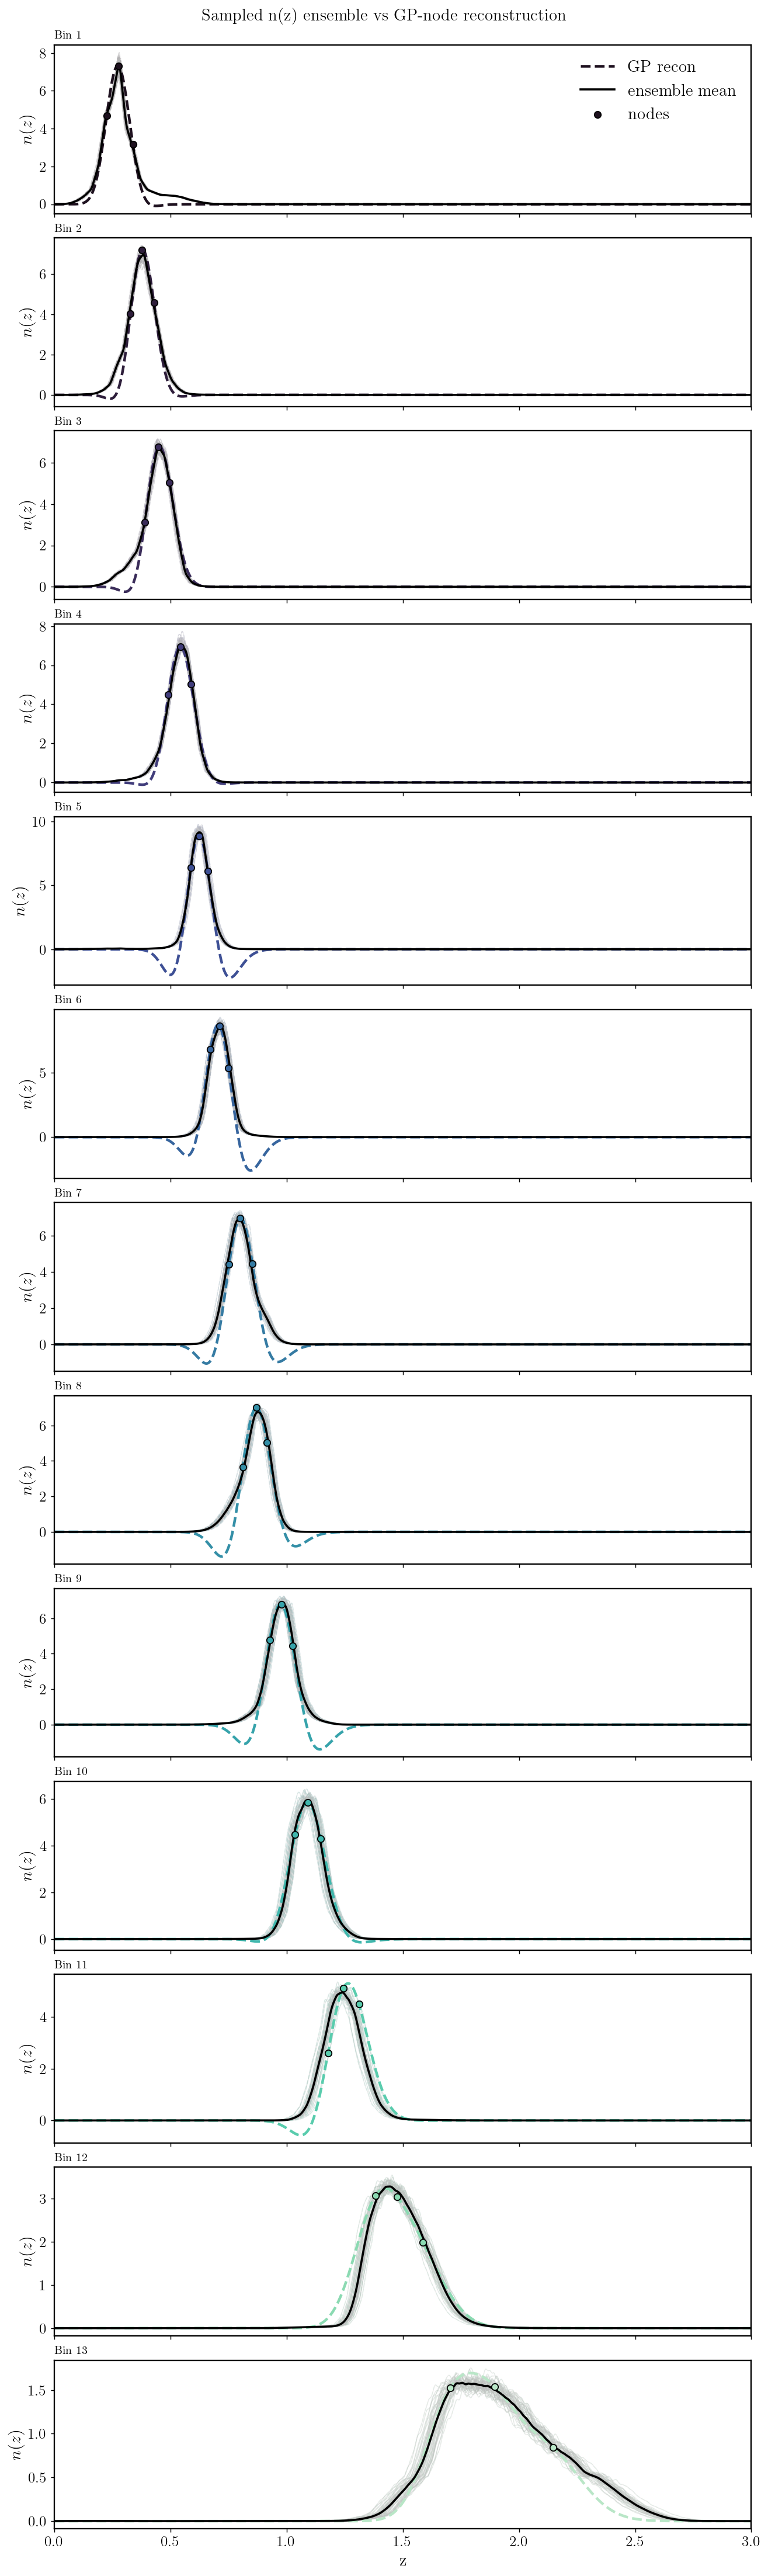

In [15]:
palette = sns.color_palette("mako", len(priors))

n_bins = len(priors)

fig, axes = plt.subplots(
    n_bins, 1,
    figsize=(10, 2.6 * n_bins),
    sharex=True,
    constrained_layout=True
)

for b in range(n_bins):
    ax = axes[b]

    arr = nz_ensemble_list[b]

    # --- Original ensemble (thin dashed)
    for i in range(arr.shape[0]):
        nz_i = arr[i] / np.trapezoid(arr[i], z_grid)
        ax.plot(z_grid, nz_i,
                color=palette[b],
                alpha=0.15, lw=1, ls="--")
        

    # --- Ensemble curves (solid, translucent)
    for i in range(arr.shape[0]):
        ax.plot(z_grid,
                arr[i] / np.trapezoid(arr[i], z_grid),
                color="silver", alpha=0.3, lw=0.8)

    # --- GP reconstruction
    ax.plot(z_grid, nz_recon[b],
            color=palette[b], ls='--', lw=2.5, label="GP recon")

    # --- Ensemble mean
    nz_mean = np.mean(
        arr / np.trapezoid(arr, z_grid, axis=1)[:, None],
        axis=0
    )
    ax.plot(z_grid, nz_mean, color="black", lw=2, label="ensemble mean")

    # --- Node locations
    z_nodes = priors[b]["z_nodes"]
    ax.scatter(z_nodes, theta_all_bins[b],
               s=40, color=palette[b],
               edgecolor="black", zorder=5,
               label="nodes")

    ax.set_ylabel(r"$n(z)$")
    
    ax.set_title(f"Bin {b+1}", loc="left", fontsize=11)
    ax.set_xlim(0, 3)

# Legend only once
axes[0].legend(frameon=False, fontsize=16)

axes[-1].set_xlabel("z")
fig.suptitle("Sampled n(z) ensemble vs GP-node reconstruction", fontsize=16)
#plt.savefig("/home/jipdebuck/plots/new_reconst.png", dpi=600)

### 3. Enforcing positivity by going to log space, while enforcing going to zero at the edges with window function

In [56]:
# Redefining the way we reconstruct n(z) to enforce positivity # 

def window_func(x):
    """
    Window function to ensure positivity.
    The form of this function is up to the user.
    """
    return x*(1-x)

def reconstruct_nz_from_nodes_gp_pos(
    z_pred,
    z_nodes,
    theta_nodes,
    window,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- set 0 for interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,          # <-- optional like your example
):
    """
    This is the "inferred by the nodes" GP:
      Train on (zmin,0), (z_nodes, theta_nodes), (zmax,0).
      Predict on z_pred.

    IMPORTANT:
    - Do NOT clip/renormalize here if you want the GP mean to pass through nodes.
    - If you need positivity/normalization, do it in the node parameterization
      (e.g., sample log-theta) or use a log-GP model.
    """
    zmin, zmax = z_bounds
    z_pred = np.asarray(z_pred, float)

    # training data (anchors)
    z_train = np.asarray(z_nodes, float)
    y_train = np.asarray(theta_nodes, float)

    X_train = x_log1p(z_train, zmax).reshape(-1, 1)
    X_pred  = x_log1p(z_pred, zmax).reshape(-1, 1)
    w_pred = window(X_pred.ravel())

    # applying window function
    w_train = window(X_train.ravel())
    y_train_log = np.log(y_train/w_train)

    kernel = kernel_fixed(kernel_class, amp=amp, ell=corr_len, nu=nu, amp_bounds=(1e-6, 10.0))

    gp = GaussianProcessRegressor(
        kernel=kernel,
        optimizer=None,
        normalize_y=False,
        alpha=float(alpha),
        copy_X_train=False,
        random_state=0,
    )
    gp.fit(X_train, y_train_log)

    if return_std:
        y_pred_log, y_std = gp.predict(X_pred, return_std=True)
        y_pred = w_pred*np.exp(y_pred_log)
        return y_pred, y_std, gp
    else:
        y_pred_log = gp.predict(X_pred, return_std=False)
        y_pred = w_pred*np.exp(y_pred_log)
        return y_pred
    
def reconstruct_all_bins_pos(
    z_pred,
    priors,
    theta_all_bins,            # list of arrays, each shape (M,)
    window,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- use 0.0 if you want interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,
):
    """
    Decode all bins at once: returns list of n_b(z_pred).
    If return_std=True, returns list of (mean,std) per bin.
    """
    out = []
    for b, pb in enumerate(priors):
        if return_std:
            mean, std, _ = reconstruct_nz_from_nodes_gp_pos(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                window=window,
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=True,
            )
            out.append((mean, std))
        else:
            nz = reconstruct_nz_from_nodes_gp_pos(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                window=window,
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=False,
            )
            out.append(nz)
    return out
    
priors = build_gp_node_priors_per_bin(
    z=z_grid,
    nz_ensemble_list=nz_ensemble_list,
    z_bounds=(0.0, 3.0),
    quantiles=(0.2, 0.5, 0.8),  # 3 nodes per bin (tune to 2–5)
)
rng = np.random.default_rng(42)

theta_all_bins = []
for b, pb in enumerate(priors):
    mu = pb["mu"]        # shape (M,)
    Sigma = pb["Sigma"]  # shape (M, M)
    theta_b = rng.multivariate_normal(mu, Sigma)
    theta_all_bins.append(theta_b)

nz_recon = reconstruct_all_bins_pos(
    z_pred=z_grid,
    priors=priors,
    theta_all_bins=theta_all_bins,
    window=window_func,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,           # <-- crucial for interpolation
)


Text(0.5, 0.98, 'Sampled n(z) ensemble vs GP-node reconstruction')

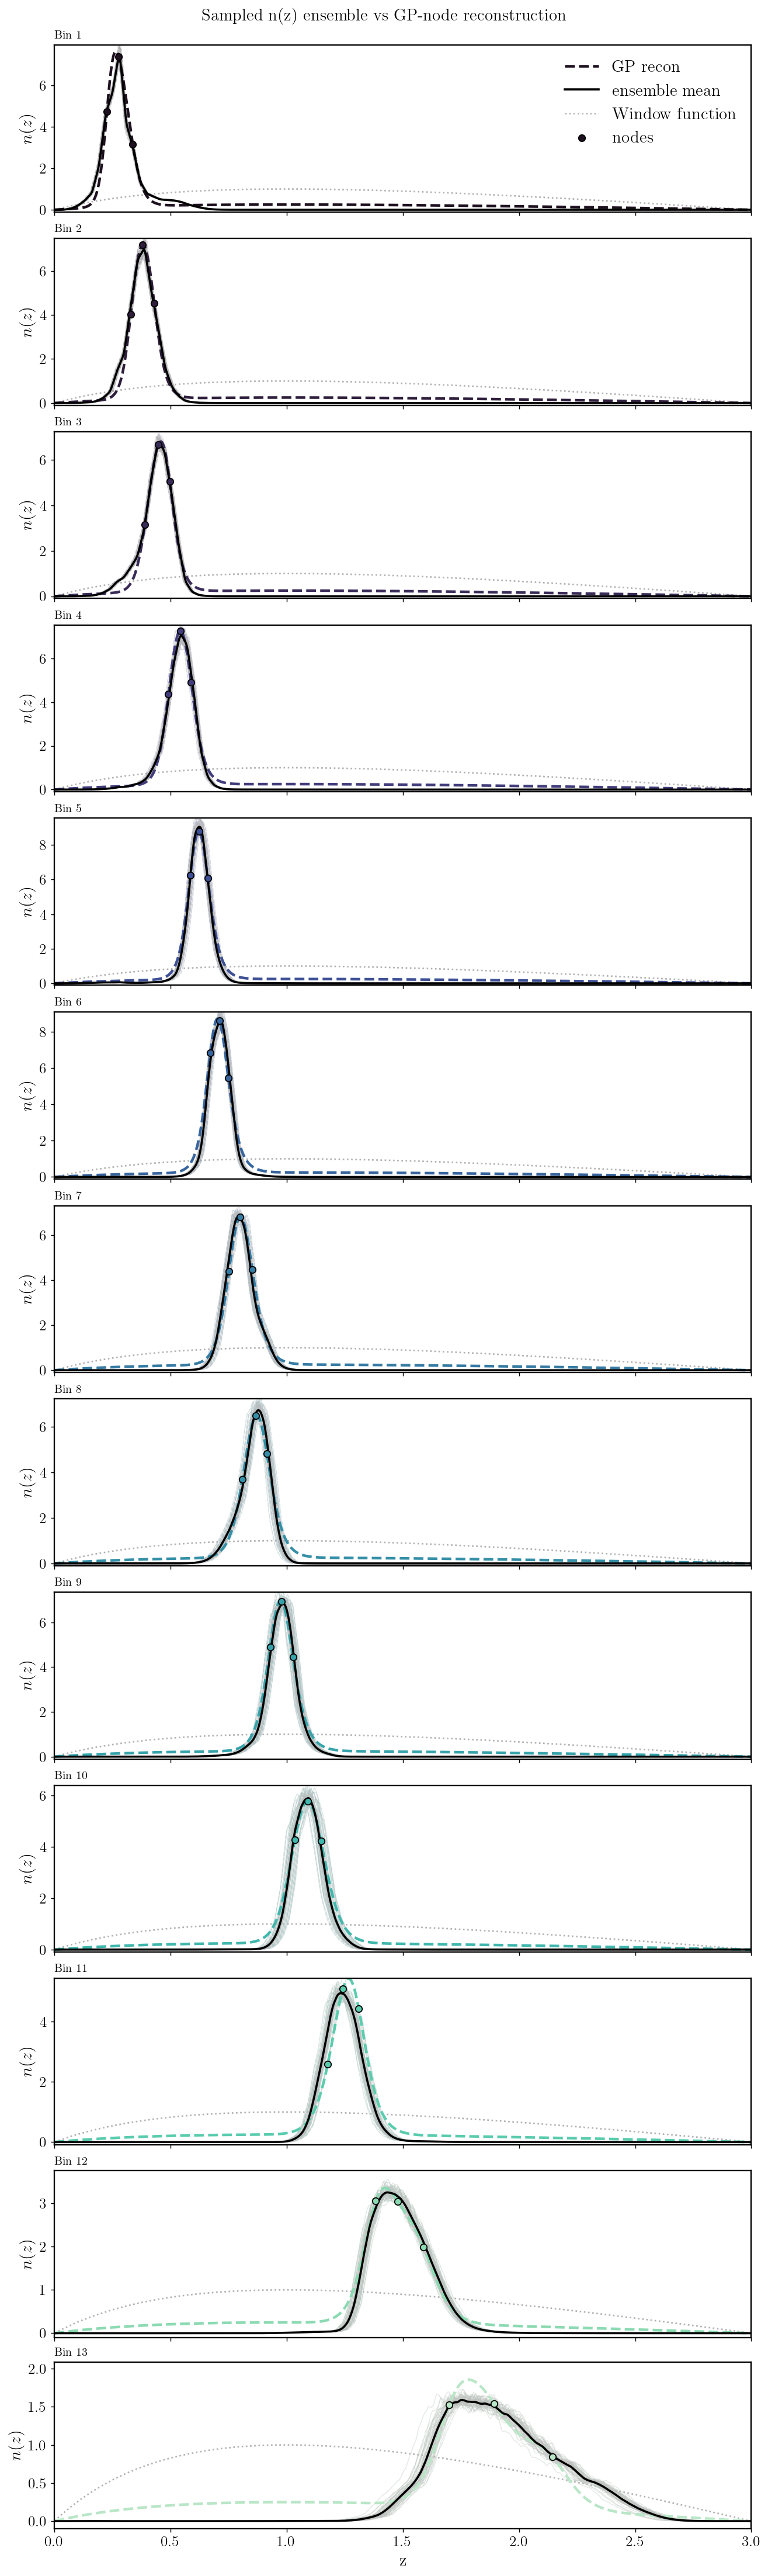

In [54]:
palette = sns.color_palette("mako", len(priors))

n_bins = len(priors)

x_grid = x_log1p(z_grid, 3)
w_grid = window_func(x_grid)
w_grid_norm = w_grid/np.max(w_grid)

fig, axes = plt.subplots(
    n_bins, 1,
    figsize=(10, 2.6 * n_bins),
    sharex=True,
    constrained_layout=True
)

for b in range(n_bins):
    ax = axes[b]

    arr = nz_ensemble_list[b]

    # --- Original ensemble (thin dashed)
    for i in range(arr.shape[0]):
        nz_i = arr[i] / np.trapezoid(arr[i], z_grid)
        ax.plot(z_grid, nz_i,
                color=palette[b],
                alpha=0.15, lw=1, ls="--")
        

    # --- Ensemble curves (solid, translucent)
    for i in range(arr.shape[0]):
        ax.plot(z_grid,
                arr[i] / np.trapezoid(arr[i], z_grid),
                color="silver", alpha=0.3, lw=0.8)

    # --- GP reconstruction
    ax.plot(z_grid, nz_recon[b],
            color=palette[b], ls='--', lw=2.5, label="GP recon")

    # --- Ensemble mean
    nz_mean = np.mean(
        arr / np.trapezoid(arr, z_grid, axis=1)[:, None],
        axis=0
    )
    ax.plot(z_grid, nz_mean, color="black", lw=2, label="ensemble mean")
    ax.plot(z_grid, w_grid_norm, color='black', alpha=0.3, linestyle='dotted', label='Window function', zorder=0)
    # --- Node locations
    z_nodes = priors[b]["z_nodes"]
    ax.scatter(z_nodes, theta_all_bins[b],
               s=40, color=palette[b],
               edgecolor="black", zorder=5,
               label="nodes")

    ax.set_ylabel(r"$n(z)$")
    
    ax.set_title(f"Bin {b+1}", loc="left", fontsize=11)
    ax.set_xlim(0, 3)
    ax.set_ylim(-0.1, np.max(nz_mean)+0.5)
# Legend only once
axes[0].legend(frameon=False, fontsize=16)

axes[-1].set_xlabel("z")
fig.suptitle("Sampled n(z) ensemble vs GP-node reconstruction", fontsize=16)

### 4. Enforcing positivity by going to log-space, while enforcing going to zero at edges with training nodes 

In [60]:
# Redefining the way we reconstruct n(z) to enforce positivity # 

def reconstruct_nz_from_nodes_gp_log(
    z_pred,
    z_nodes,
    theta_nodes,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- set 0 for interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,          # <-- optional like your example
):
    """
    This is the "inferred by the nodes" GP:
      Train on (zmin,0), (z_nodes, theta_nodes), (zmax,0).
      Predict on z_pred.

    IMPORTANT:
    - Do NOT clip/renormalize here if you want the GP mean to pass through nodes.
    - If you need positivity/normalization, do it in the node parameterization
      (e.g., sample log-theta) or use a log-GP model.
    """
    zmin, zmax = z_bounds
    z_pred = np.asarray(z_pred, float)

    # training data (anchors)
    z_train = np.concatenate([[zmin], np.asarray(z_nodes, float), [zmax]])
    y_train = np.concatenate([[1e-7], np.asarray(theta_nodes, float), [1e-7]])

    X_train = x_log1p(z_train, zmax).reshape(-1, 1)
    X_pred  = x_log1p(z_pred, zmax).reshape(-1, 1)

    y_train_log = np.log(y_train)

    kernel = kernel_fixed(kernel_class, amp=amp, ell=corr_len, nu=nu, amp_bounds=(1e-6, 10.0))

    gp = GaussianProcessRegressor(
        kernel=kernel,
        optimizer=None,
        normalize_y=False,
        alpha=float(alpha),
        copy_X_train=False,
        random_state=0,
    )
    gp.fit(X_train, y_train_log)

    if return_std:
        y_pred_log, y_std = gp.predict(X_pred, return_std=True)
        y_pred = np.exp(y_pred_log)
        return y_pred, y_std, gp
    else:
        y_pred_log = gp.predict(X_pred, return_std=False)
        y_pred = np.exp(y_pred_log)
        return y_pred
    
def reconstruct_all_bins_log(
    z_pred,
    priors,
    theta_all_bins,            # list of arrays, each shape (M,)
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- use 0.0 if you want interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,
):
    """
    Decode all bins at once: returns list of n_b(z_pred).
    If return_std=True, returns list of (mean,std) per bin.
    """
    out = []
    for b, pb in enumerate(priors):
        if return_std:
            mean, std, _ = reconstruct_nz_from_nodes_gp_log(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=True,
            )
            out.append((mean, std))
        else:
            nz = reconstruct_nz_from_nodes_gp_log(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=False,
            )
            out.append(nz)
    return out
    
priors = build_gp_node_priors_per_bin(
    z=z_grid,
    nz_ensemble_list=nz_ensemble_list,
    z_bounds=(0.0, 3.0),
    quantiles=(0.2, 0.5, 0.8),  # 3 nodes per bin (tune to 2–5)
)
rng = np.random.default_rng(42)

theta_all_bins = []
for b, pb in enumerate(priors):
    mu = pb["mu"]        # shape (M,)
    Sigma = pb["Sigma"]  # shape (M, M)
    theta_b = rng.multivariate_normal(mu, Sigma)
    theta_all_bins.append(theta_b)

nz_recon = reconstruct_all_bins_log(
    z_pred=z_grid,
    priors=priors,
    theta_all_bins=theta_all_bins,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,           # <-- crucial for interpolation
)


Text(0.5, 0.98, 'Sampled n(z) ensemble vs GP-node reconstruction')

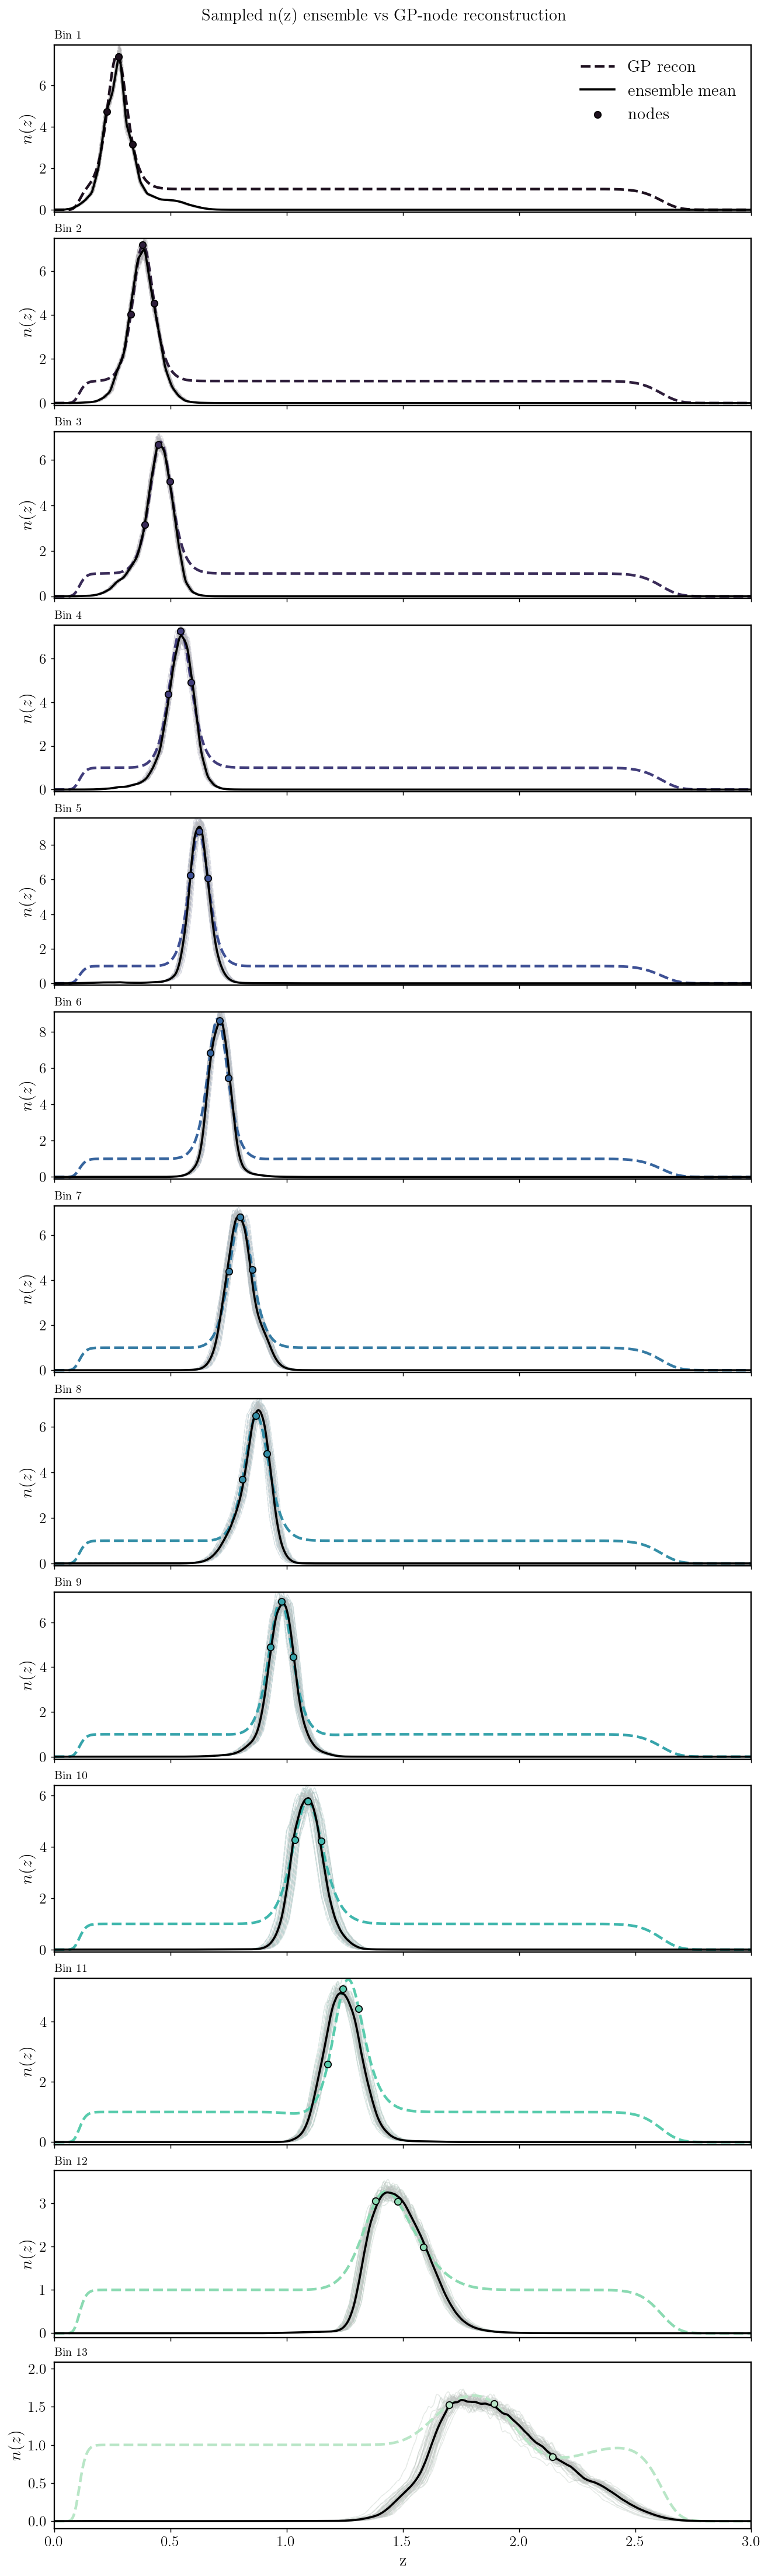

In [61]:
palette = sns.color_palette("mako", len(priors))

n_bins = len(priors)

fig, axes = plt.subplots(
    n_bins, 1,
    figsize=(10, 2.6 * n_bins),
    sharex=True,
    constrained_layout=True
)

for b in range(n_bins):
    ax = axes[b]

    arr = nz_ensemble_list[b]

    # --- Original ensemble (thin dashed)
    for i in range(arr.shape[0]):
        nz_i = arr[i] / np.trapezoid(arr[i], z_grid)
        ax.plot(z_grid, nz_i,
                color=palette[b],
                alpha=0.15, lw=1, ls="--")
        

    # --- Ensemble curves (solid, translucent)
    for i in range(arr.shape[0]):
        ax.plot(z_grid,
                arr[i] / np.trapezoid(arr[i], z_grid),
                color="silver", alpha=0.3, lw=0.8)

    # --- GP reconstruction
    ax.plot(z_grid, nz_recon[b],
            color=palette[b], ls='--', lw=2.5, label="GP recon")

    # --- Ensemble mean
    nz_mean = np.mean(
        arr / np.trapezoid(arr, z_grid, axis=1)[:, None],
        axis=0
    )
    ax.plot(z_grid, nz_mean, color="black", lw=2, label="ensemble mean")
    
    # --- Node locations
    z_nodes = priors[b]["z_nodes"]
    ax.scatter(z_nodes, theta_all_bins[b],
               s=40, color=palette[b],
               edgecolor="black", zorder=5,
               label="nodes")

    ax.set_ylabel(r"$n(z)$")
    
    ax.set_title(f"Bin {b+1}", loc="left", fontsize=11)
    ax.set_xlim(0, 3)
    ax.set_ylim(-0.1, np.max(nz_mean)+0.5)
# Legend only once
axes[0].legend(frameon=False, fontsize=16)

axes[-1].set_xlabel("z")
fig.suptitle("Sampled n(z) ensemble vs GP-node reconstruction", fontsize=16)

### 5. Enforcing positivity by going to squared space, while ensuring going to zero with training nodes at edges

In [44]:
def reconstruct_nz_from_nodes_gp_square(
    z_pred,
    z_nodes,
    theta_nodes,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- set 0 for interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,          # <-- optional like your example
):
    """
    This is the "inferred by the nodes" GP:
      Train on (zmin,0), (z_nodes, theta_nodes), (zmax,0).
      Predict on z_pred.

    IMPORTANT:
    - Do NOT clip/renormalize here if you want the GP mean to pass through nodes.
    - If you need positivity/normalization, do it in the node parameterization
      (e.g., sample log-theta) or use a log-GP model.
    """
    zmin, zmax = z_bounds
    z_pred = np.asarray(z_pred, float)

    # training data (anchors)
    z_train = np.concatenate([[zmin], np.asarray(z_nodes, float), [zmax]])
    y_train_squareroot = np.concatenate([[0], np.asarray(np.sqrt(theta_nodes), float), [0]])

    X_train = x_log1p(z_train, zmax).reshape(-1, 1)
    X_pred  = x_log1p(z_pred, zmax).reshape(-1, 1)

    kernel = kernel_fixed(kernel_class, amp=amp, ell=corr_len, nu=nu, amp_bounds=(1e-6, 10.0))

    gp = GaussianProcessRegressor(
        kernel=kernel,
        optimizer=None,
        normalize_y=False,
        alpha=float(alpha),
        copy_X_train=False,
        random_state=0,
    )
    gp.fit(X_train, y_train_squareroot)

    if return_std:
        y_pred_squareroot, y_std = gp.predict(X_pred, return_std=True)
        y_pred = y_pred_squareroot**2
        return y_pred, y_std, gp
    else:
        y_pred_squareroot = gp.predict(X_pred, return_std=False)
        y_pred = y_pred_squareroot**2
        return y_pred

def reconstruct_all_bins_square(
    z_pred,
    priors,
    theta_all_bins,            # list of arrays, each shape (M,)
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- use 0.0 if you want interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,
):
    """
    Decode all bins at once: returns list of n_b(z_pred).
    If return_std=True, returns list of (mean,std) per bin.
    """
    out = []
    for b, pb in enumerate(priors):
        if return_std:
            mean, std, _ = reconstruct_nz_from_nodes_gp_square(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=True,
            )
            out.append((mean, std))
        else:
            nz = reconstruct_nz_from_nodes_gp_square(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=False,
            )
            out.append(nz)
    return out
    
priors = build_gp_node_priors_per_bin(
    z=z_grid,
    nz_ensemble_list=nz_ensemble_list,
    z_bounds=(0.0, 3.0),
    quantiles=(0.2, 0.5, 0.8),  # 3 nodes per bin (tune to 2–5)
)
rng = np.random.default_rng(42)

theta_all_bins = []
for b, pb in enumerate(priors):
    mu = pb["mu"]        # shape (M,)
    Sigma = pb["Sigma"]  # shape (M, M)
    theta_b = rng.multivariate_normal(mu, Sigma)
    theta_all_bins.append(theta_b)

nz_recon = reconstruct_all_bins_square(
    z_pred=z_grid,
    priors=priors,
    theta_all_bins=theta_all_bins,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,           # <-- crucial for interpolation
)


Text(0.5, 0.98, 'Sampled n(z) ensemble vs GP-node reconstruction')

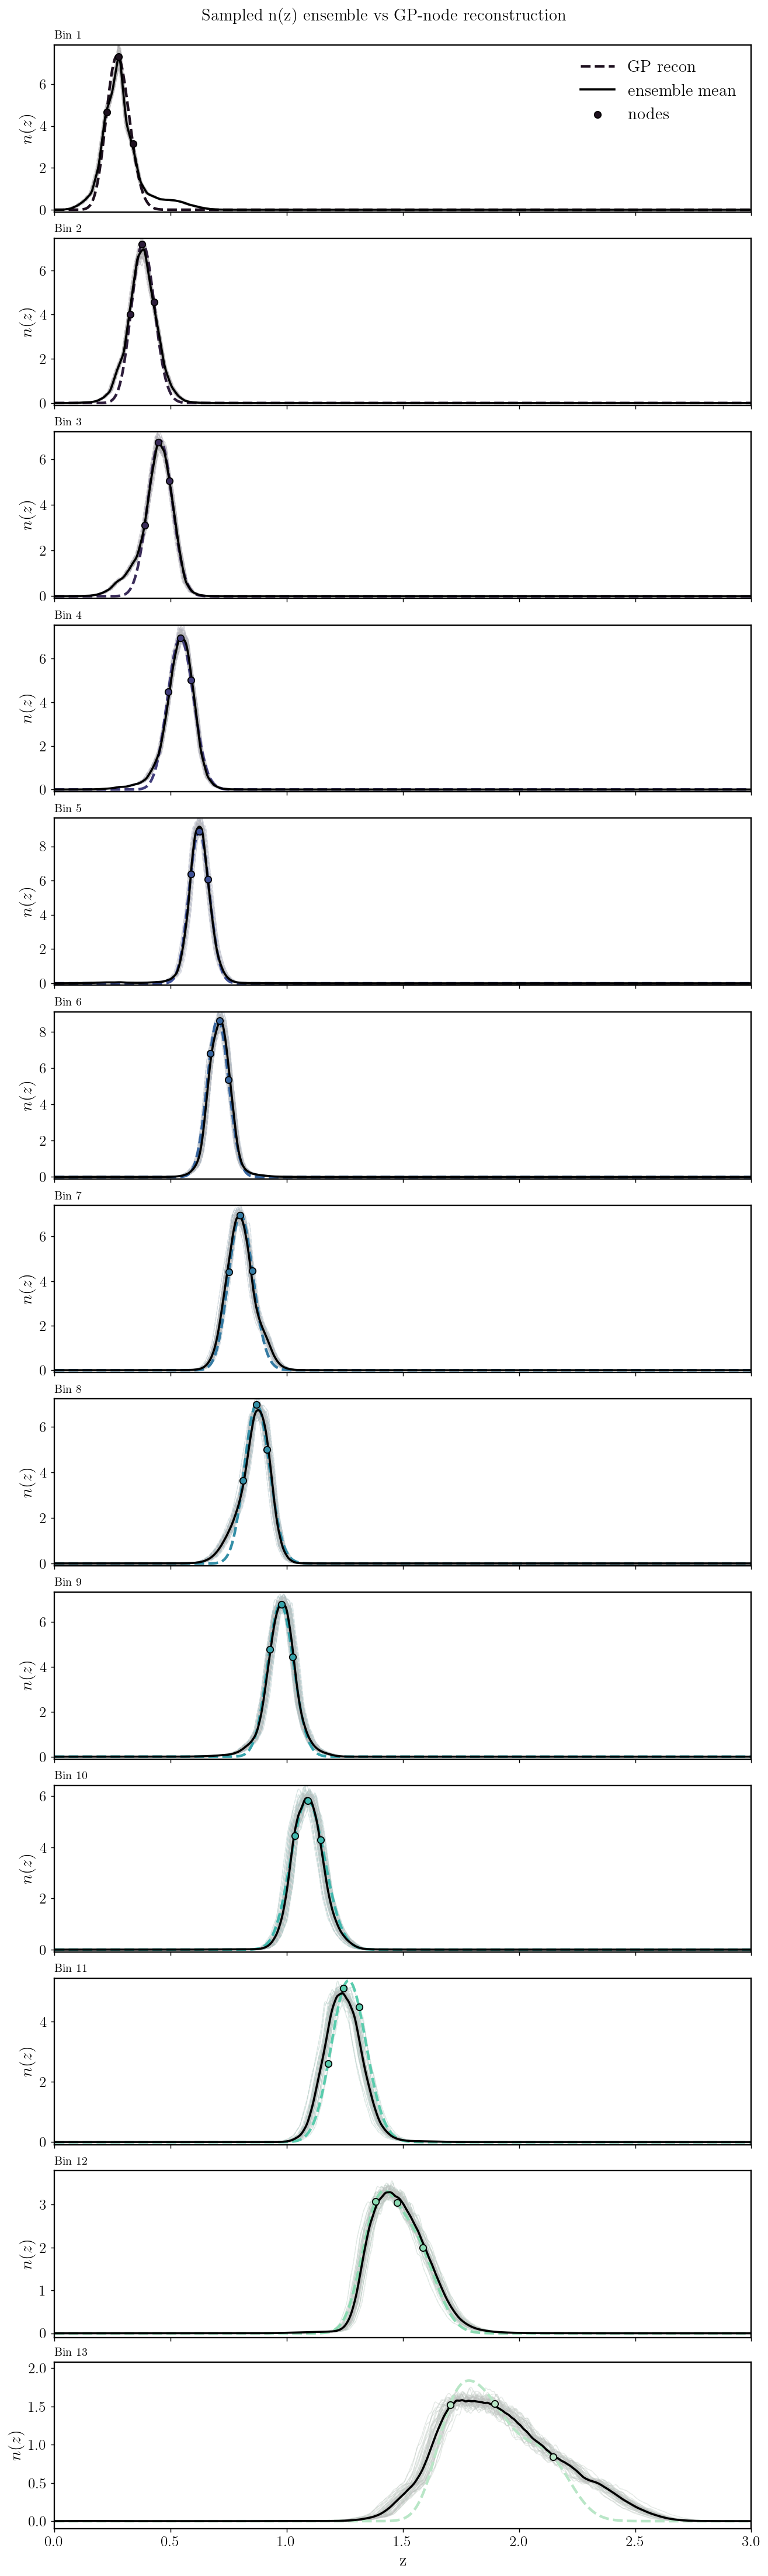

In [19]:
palette = sns.color_palette("mako", len(priors))

n_bins = len(priors)

fig, axes = plt.subplots(
    n_bins, 1,
    figsize=(10, 2.6 * n_bins),
    sharex=True,
    constrained_layout=True
)

for b in range(n_bins):
    ax = axes[b]

    arr = nz_ensemble_list[b]

    # --- Original ensemble (thin dashed)
    for i in range(arr.shape[0]):
        nz_i = arr[i] / np.trapezoid(arr[i], z_grid)
        ax.plot(z_grid, nz_i,
                color=palette[b],
                alpha=0.15, lw=1, ls="--")
        

    # --- Ensemble curves (solid, translucent)
    for i in range(arr.shape[0]):
        ax.plot(z_grid,
                arr[i] / np.trapezoid(arr[i], z_grid),
                color="silver", alpha=0.3, lw=0.8)

    # --- GP reconstruction
    ax.plot(z_grid, nz_recon[b],
            color=palette[b], ls='--', lw=2.5, label="GP recon")

    # --- Ensemble mean
    nz_mean = np.mean(
        arr / np.trapezoid(arr, z_grid, axis=1)[:, None],
        axis=0
    )
    ax.plot(z_grid, nz_mean, color="black", lw=2, label="ensemble mean")
    
    # --- Node locations
    z_nodes = priors[b]["z_nodes"]
    ax.scatter(z_nodes, theta_all_bins[b],
               s=40, color=palette[b],
               edgecolor="black", zorder=5,
               label="nodes")

    ax.set_ylabel(r"$n(z)$")
    
    ax.set_title(f"Bin {b+1}", loc="left", fontsize=11)
    ax.set_xlim(0, 3)
    ax.set_ylim(-0.1, np.max(nz_mean)+0.5)
# Legend only once
axes[0].legend(frameon=False, fontsize=16)

axes[-1].set_xlabel("z")
fig.suptitle("Sampled n(z) ensemble vs GP-node reconstruction", fontsize=16)

### 6. Implementing the prior for DR1, i.e. 13 --> 6 bins

In [20]:
# Load in the DR1 n(z) 
z, nz = el.phz.redshift_distributions('/home/jipdebuck/nz_example.fits')

# Normalize both dndz_pos and dndz_she
dndz_pos_norm = normalize_dndz(nz, z)
dndz_she_norm = normalize_dndz(nz, z)

# Resampling the normalized dndz with 100 values
my_dndz_pos_norm = resample_dndz(dndz_pos_norm, z, zs)
my_dndz_she_norm = resample_dndz(dndz_she_norm, z, zs)


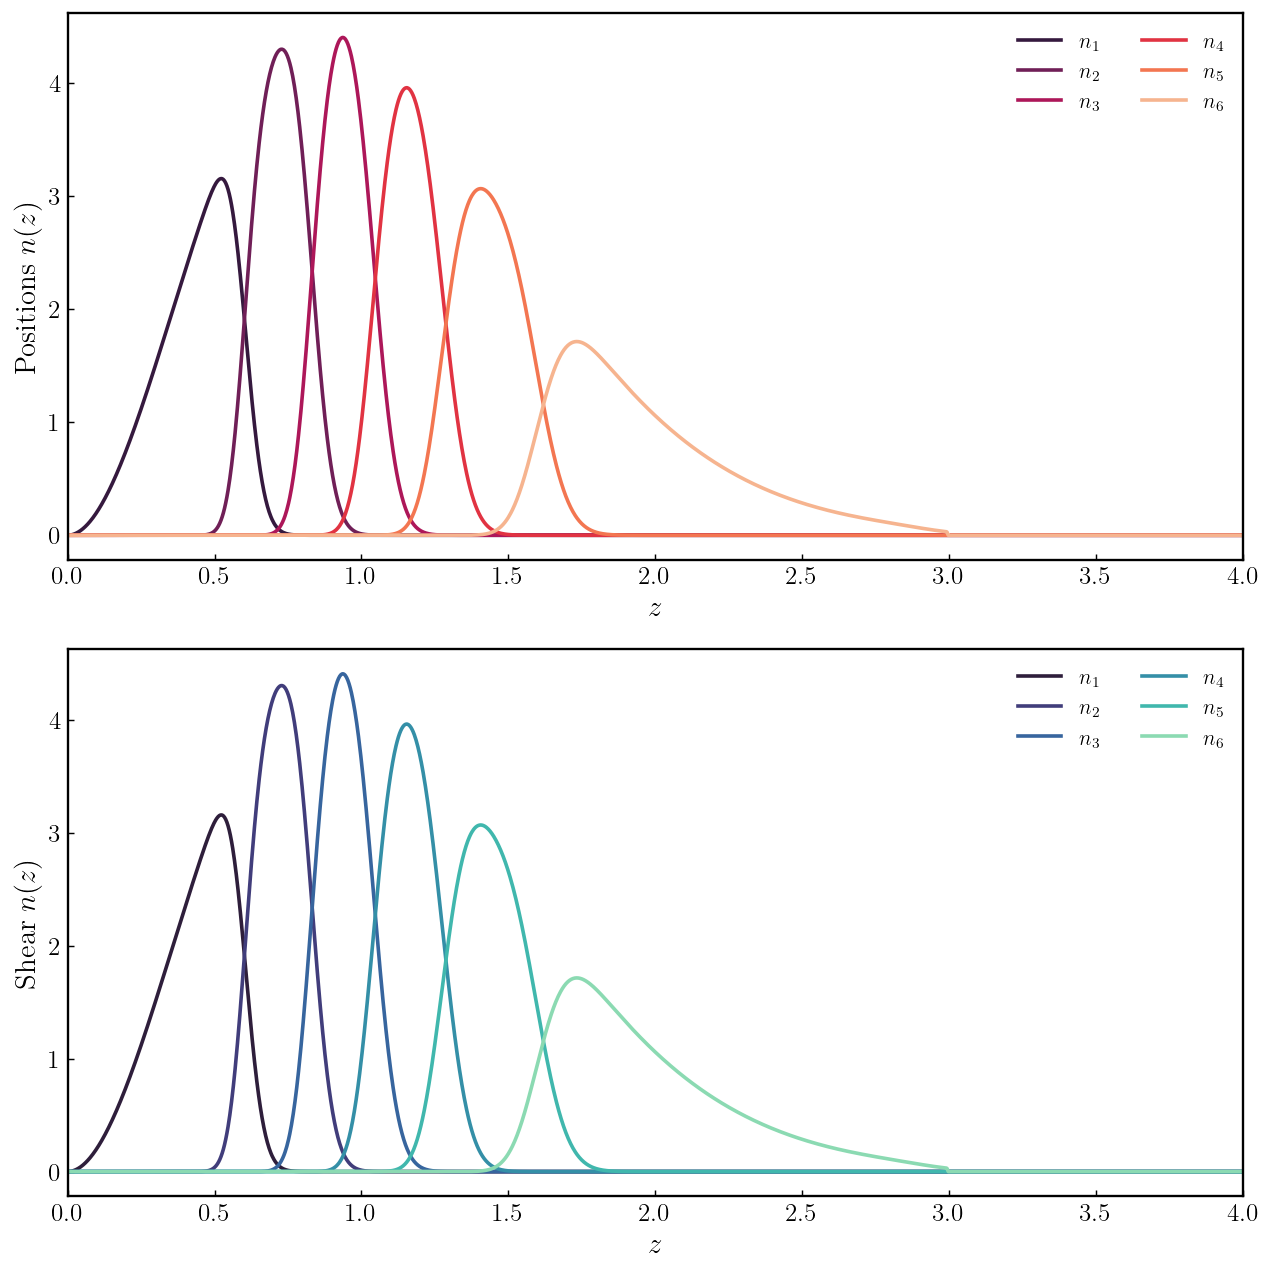

In [21]:
# Plotting of original n(z) distributions #

fig, axs = plt.subplots(2, 1, figsize=(10, 10))

# Customize tick parameters for both axes
for ax in axs.flatten():
    ax.tick_params(axis='both', which='both', direction='in')

# Plot positions n(z)
for i, (key, color) in enumerate(zip(dndz_pos_norm.keys(), sns.color_palette("rocket", len(dndz_pos_norm)))):
    axs[0].plot(z, dndz_pos_norm[key], label=f'$n_{{{i+1}}}$', linewidth=2, color=color)

# Plot shear n(z)
for j, (key, color) in enumerate(zip(dndz_she_norm.keys(), sns.color_palette("mako", len(dndz_she_norm)))):
    axs[1].plot(z, dndz_she_norm[key], label=f'$n_{{{j+1}}}$', linewidth=2, color=color)

# Set labels and legends
axs[0].set_xlabel(r'$z$')
axs[0].set_ylabel(r'Positions $n(z)$')
axs[0].set_xlim(0, 4)
axs[0].legend(frameon=False, ncol=2)

axs[1].set_xlabel(r'$z$')
axs[1].set_ylabel(r'Shear $n(z)$')
axs[1].set_xlim(0, 4)
axs[1].legend(frameon=False, ncol=2)

plt.tight_layout()
plt.show()

In [22]:
# Define parameters for GP reconstruction #

z_meds = []   # positions of median redshift for each bin
n_meds = []   # height of n(z) at median redshift for each bin

for key, nz in dndz_she_norm.items():
    # --- CDF & median node ---
    cdf = integrate.cumulative_trapezoid(nz, z, initial=0)
    cdf /= cdf[-1]
    z_med = np.interp(0.5, cdf, z)
    n_med = nz[np.argmin(np.abs(z - z_med))]
    z_meds.append(z_med)
    n_meds.append(n_med)

corr_len = 0.03                                # correlation length for the GP kernel
z_bounds = (0,3)                              # bounds for the redshift
z_pred = np.linspace(0, 3, 400)       # prediction points for GP
alpha = 1e-8                                  # noise level during fitting 
kernel_class = RBF
nu = 1.5                                      # necessary for Matern only, defines smoothness 
const_value = 0.04                            # amplitude of constant kernel
const_bounds = (1e-4, 1.0)                    # bounds for constant kernel amplitude

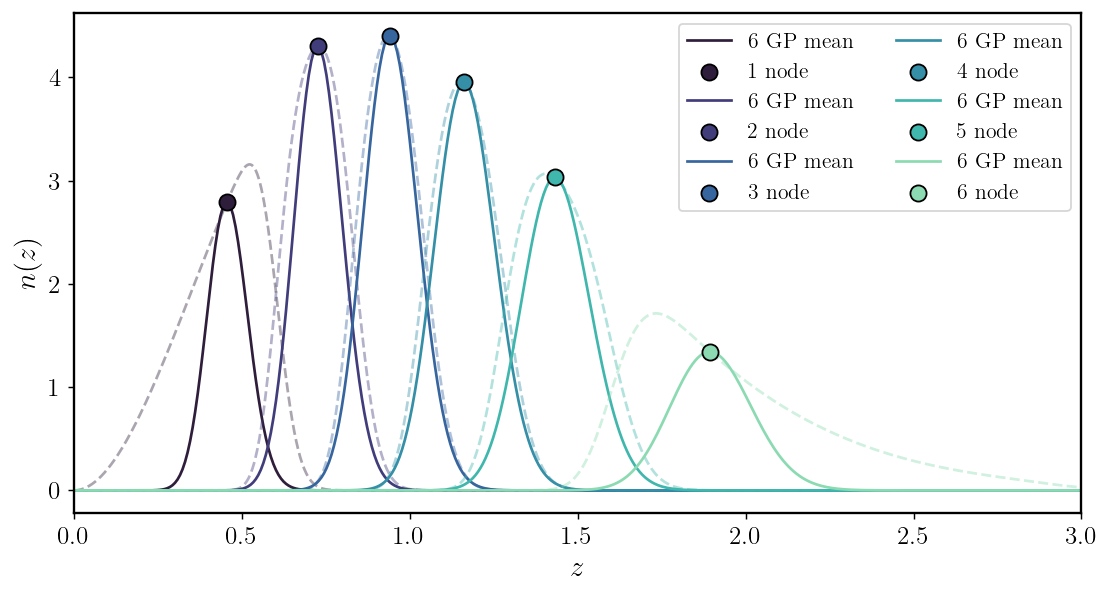

In [23]:
# GP reconstruction and plotting of results #

# Perform GP reconstruction #
priors, predictions = build_gp_nz(n_meds, z_meds, corr_len, z_bounds, z_pred, alpha, kernel_class, nu, const_value, const_bounds)

# Plot GP reconstruction results #
palette = sns.color_palette("mako", 6)
fig, ax = plt.subplots(figsize=(10, 5))

for j, nz in enumerate(n_meds):
    y_pred, y_std = predictions[j]
    X_train, y_train = z_meds[j], n_meds[j]

    ax.plot(z_pred, y_pred, color=palette[j], label=f"{key} GP mean")
    #ax.fill_between(z_pred.ravel(), (y_pred - y_std).ravel(), (y_pred + y_std).ravel(),
    #                color=palette[j], alpha=0.2)

    ax.plot(z, dndz_she_norm[j+1], '--', color=palette[j], alpha=0.4)
    ax.scatter(X_train, y_train, color=palette[j], edgecolor='black', s=80, zorder=3, label=f"{j+1} node")

ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$n(z)$")
ax.set_xlim(0, 3)
ax.legend(loc="upper right", ncol=2)
plt.show()

In [ ]:
# Creating a list of plausible n(z) realizations

z_ens_list, nz_ensemble_list = zip(*[
    generate_bin1_ensemble(
        N_ens=50, 
        nz=dndz_she_norm[i], 
        N_z=3001
    )
    for i in range(1, 7)
])

In [27]:
# Building the prior for the heights of the training nodes from the n(z) ensemble

priors = build_gp_node_priors_per_bin(
    z=z_grid,
    nz_ensemble_list=nz_ensemble_list,
    z_bounds=(0.0, 3.0),
    quantiles=(0.2, 0.5, 0.8),  # 3 nodes per bin (tune to 2–5)
)

rng = np.random.default_rng(42)

theta_all_bins = []
for b, pb in enumerate(priors):
    mu = pb["mu"]        # shape (M,)
    Sigma = pb["Sigma"]  # shape (M, M)
    theta_b = rng.multivariate_normal(mu, Sigma)
    theta_all_bins.append(theta_b)

nz_recon = reconstruct_all_bins(
    z_pred=z_grid,
    priors=priors,
    theta_all_bins=theta_all_bins,
    z_bounds=(0.0, 3.0),
    corr_len=0.035,
    amp=0.04,
    alpha=0.0,           # <-- crucial for interpolation
)

Text(0.5, 0.98, 'Sampled n(z) ensemble vs GP-node reconstruction')

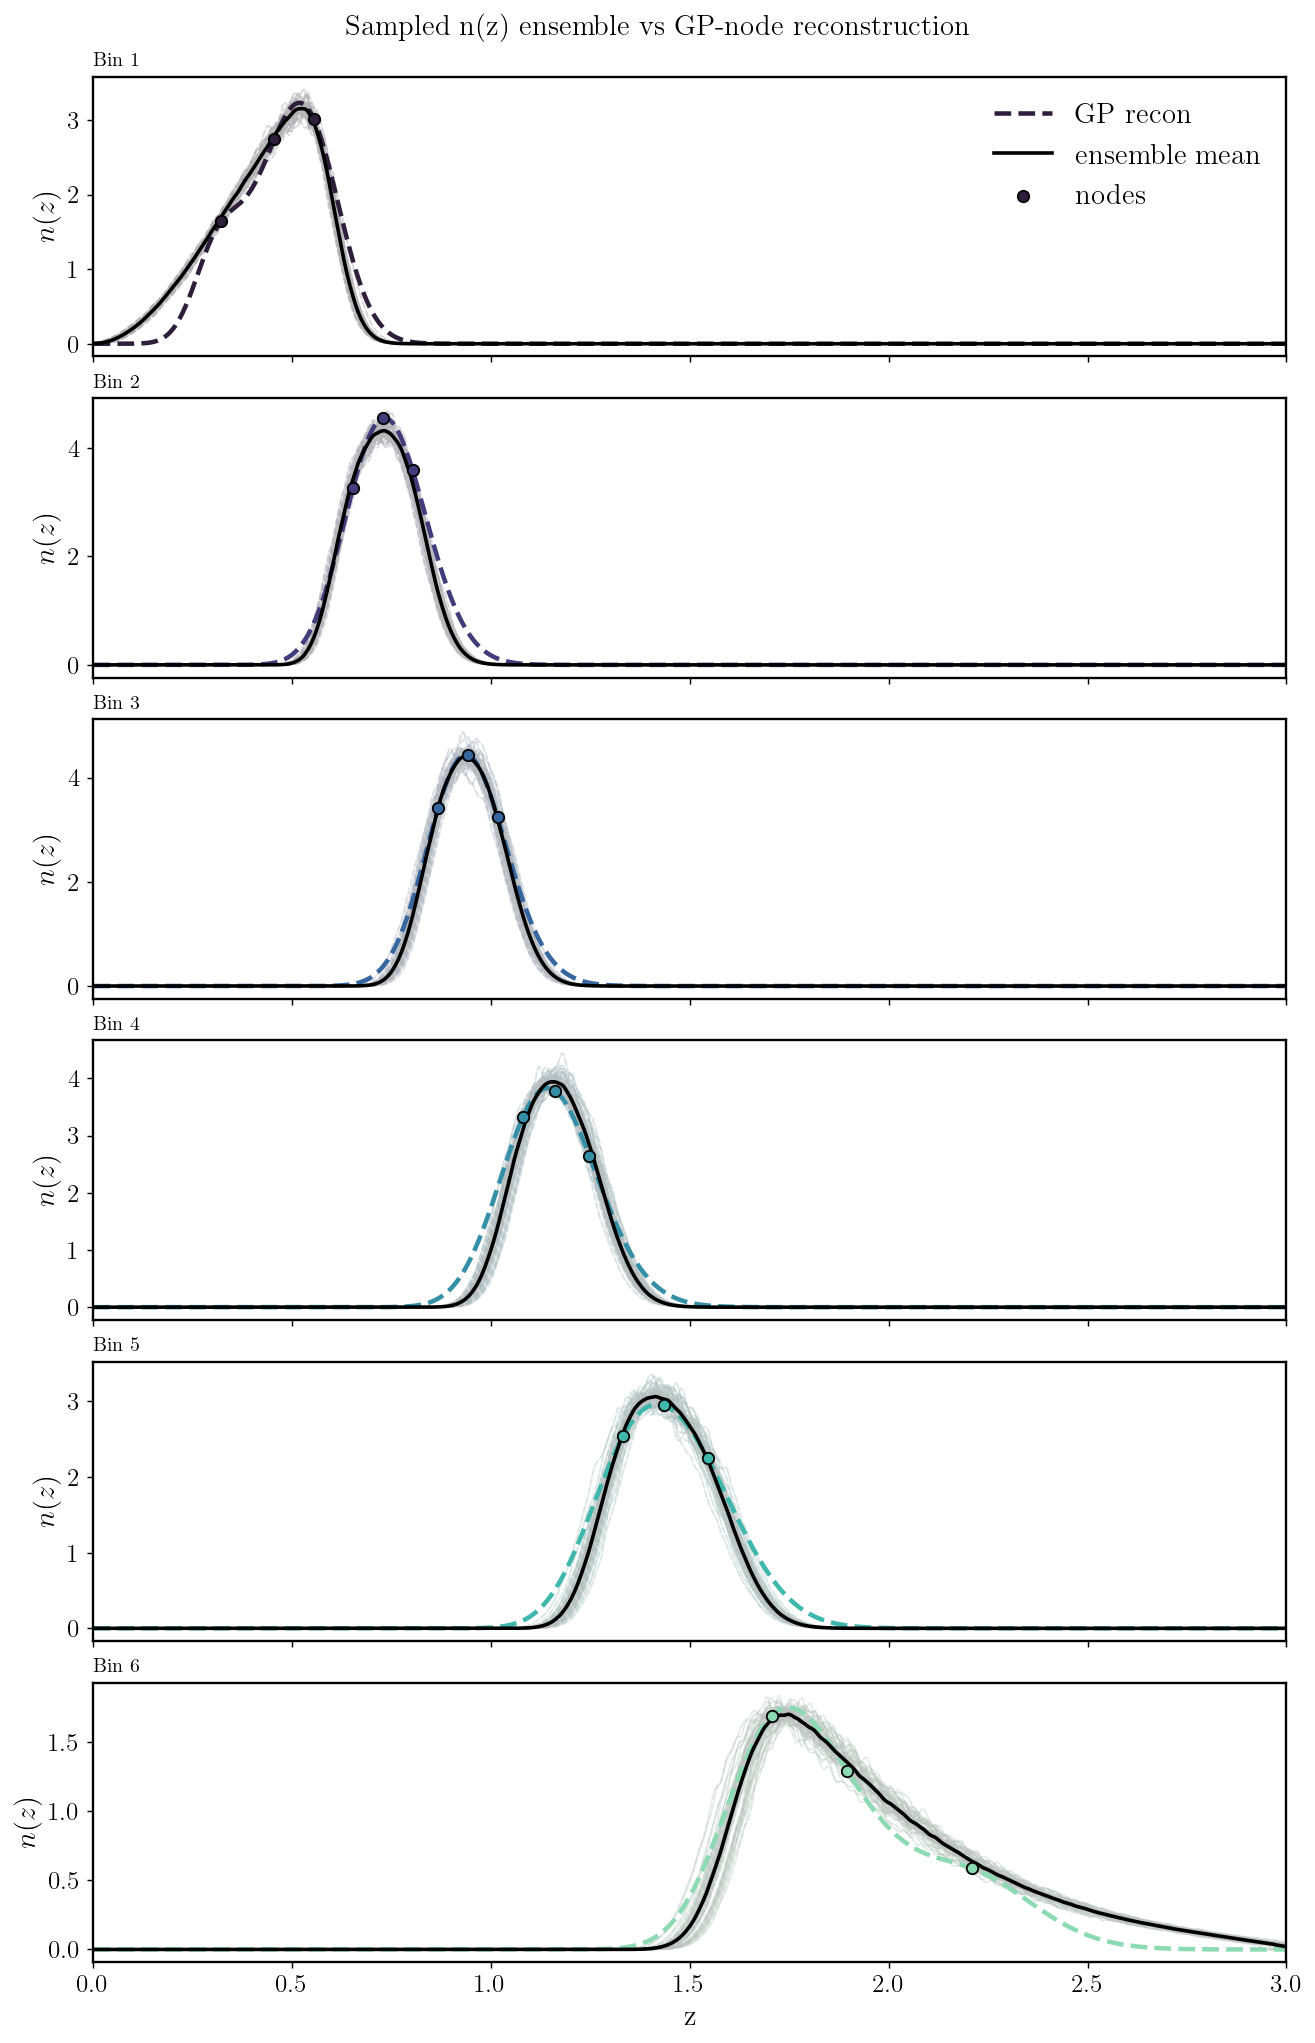

In [28]:
# Plotting the reconstructions per bin

palette = sns.color_palette("mako", len(priors))

n_bins = len(priors)

fig, axes = plt.subplots(
    n_bins, 1,
    figsize=(10, 2.6 * n_bins),
    sharex=True,
    constrained_layout=True
)

for b in range(n_bins):
    ax = axes[b]

    arr = nz_ensemble_list[b]

    # --- Original ensemble (thin dashed)
    for i in range(arr.shape[0]):
        nz_i = arr[i] / np.trapezoid(arr[i], z_grid)
        ax.plot(z_grid, nz_i,
                color=palette[b],
                alpha=0.15, lw=1, ls="--")
        

    # --- Ensemble curves (solid, translucent)
    for i in range(arr.shape[0]):
        ax.plot(z_grid,
                arr[i] / np.trapezoid(arr[i], z_grid),
                color="silver", alpha=0.3, lw=0.8)

    # --- GP reconstruction
    ax.plot(z_grid, nz_recon[b],
            color=palette[b], ls='--', lw=2.5, label="GP recon")

    # --- Ensemble mean
    nz_mean = np.mean(
        arr / np.trapezoid(arr, z_grid, axis=1)[:, None],
        axis=0
    )
    ax.plot(z_grid, nz_mean, color="black", lw=2, label="ensemble mean")

    # --- Node locations
    z_nodes = priors[b]["z_nodes"]
    ax.scatter(z_nodes, theta_all_bins[b],
               s=40, color=palette[b],
               edgecolor="black", zorder=5,
               label="nodes")

    ax.set_ylabel(r"$n(z)$")
    
    ax.set_title(f"Bin {b+1}", loc="left", fontsize=11)
    ax.set_xlim(0, 3)

# Legend only once
axes[0].legend(frameon=False, fontsize=16)

axes[-1].set_xlabel("z")
fig.suptitle("Sampled n(z) ensemble vs GP-node reconstruction", fontsize=16)
#plt.savefig("/home/jipdebuck/plots/new_reconst.png", dpi=600)

### 7. Using Kernel Density Estimation (KDE) to estimate the 2D density of the ensemble 

Reconstructing for bin 1
Reconstructing for bin 2
Reconstructing for bin 3
Reconstructing for bin 4
Reconstructing for bin 5
Reconstructing for bin 6
Reconstructing for bin 7
Reconstructing for bin 8
Reconstructing for bin 9
Reconstructing for bin 10
Reconstructing for bin 11
Reconstructing for bin 12
Reconstructing for bin 13


(0.183, 0.221)

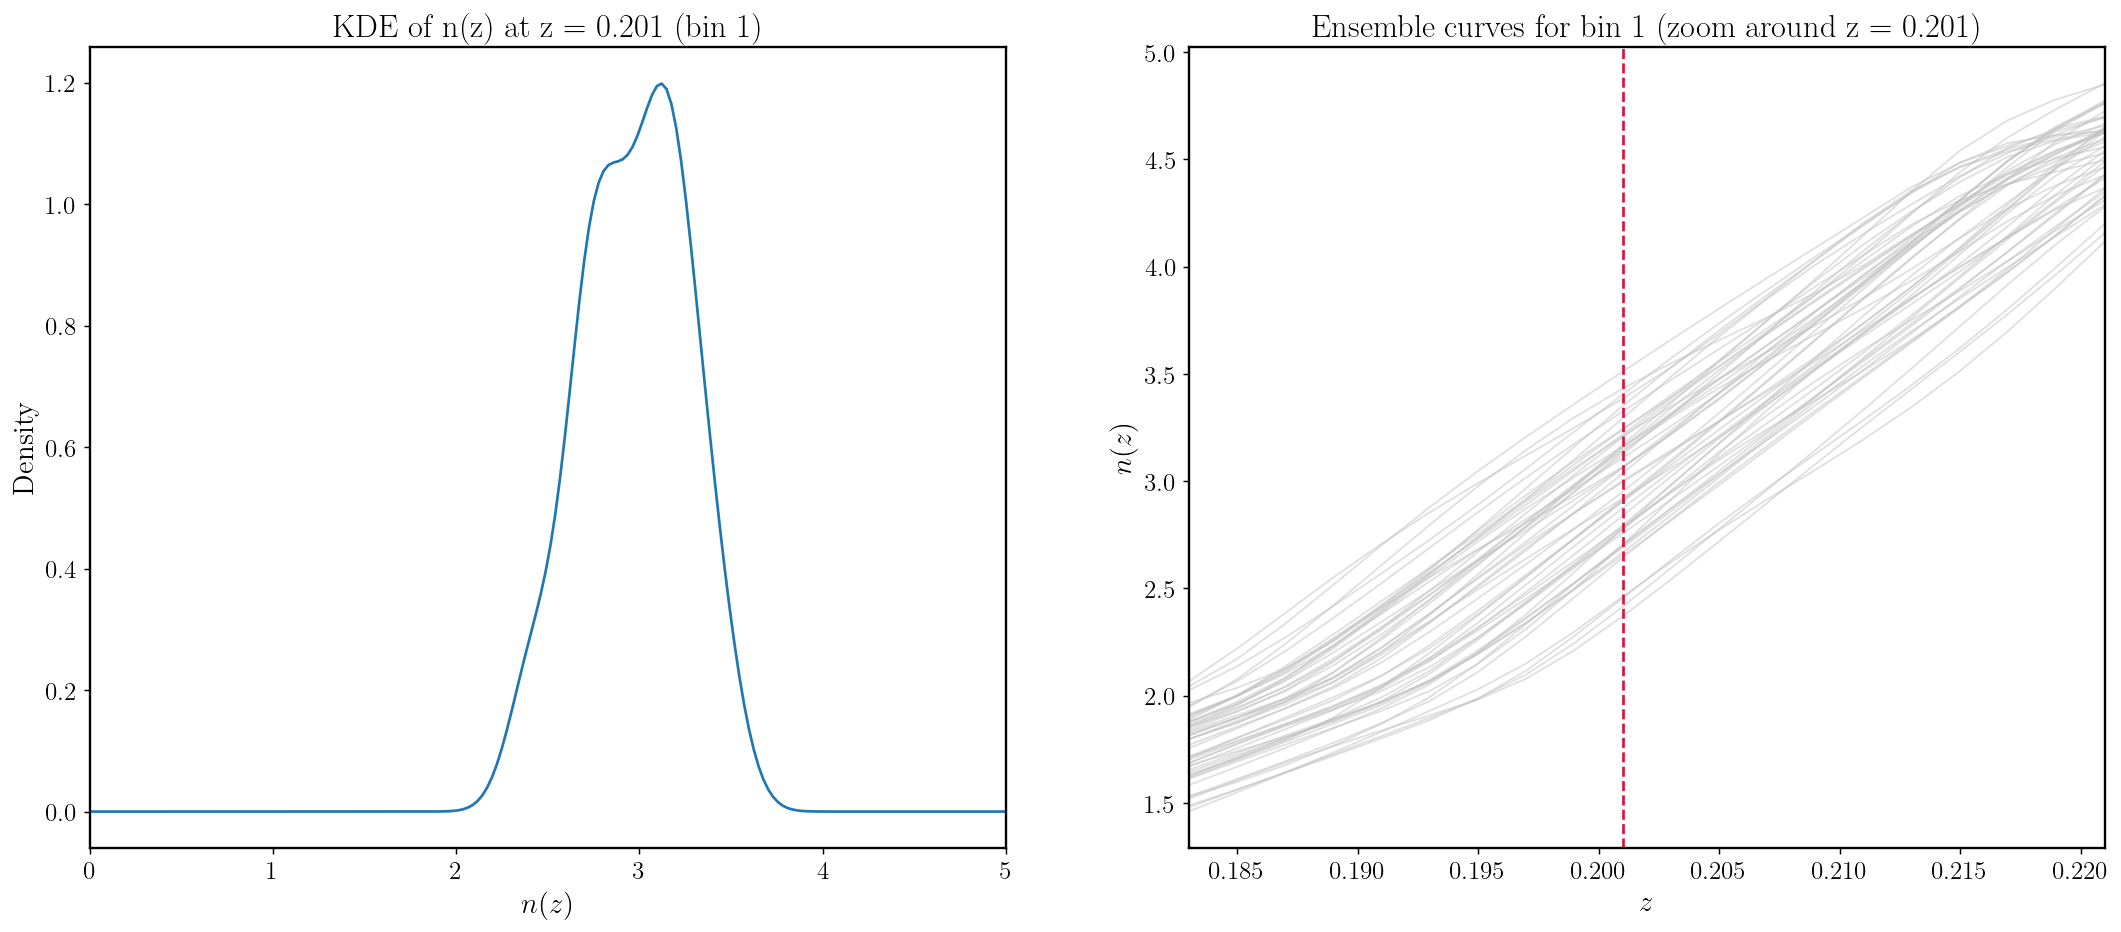

In [18]:
def compute_1d_kdes_for_bin(z, ensemble):
    N_ens, N_z = ensemble.shape
    kdes = []
    for j in range(N_z):
        samples = ensemble[:, j]          # the 50 ensemble values at this specific z
        kde = gaussian_kde(samples)       #compute the KDE at this specific z using the 50 values 
        kdes.append(kde) #we get a KDE for each redshift z in the given bin
    return kdes


kde_1d_bins = []

for b in range(13):
    print(f"Reconstructing for bin {b+1}")
    z = z_ens_list[b]                     
    ensemble = nz_ensemble_list[b]        
    kdes = compute_1d_kdes_for_bin(z, ensemble) # computing the KDE in a specific bin
    kde_1d_bins.append((z, kdes))


bin_index = 0
z, kdes = kde_1d_bins[bin_index] # kdes for first bin evaluated at each redshift in the first bin

j = 100  # one specific redshift 
kde = kdes[j]

# Evaluate density on a y-grid
y_grid = np.linspace(0, nz_ensemble_list[bin_index][:, j].max()*1.5, 200) 
density = kde(y_grid)


fig, axes = plt.subplots(1, 2, figsize=(20, 8))
axes[0].plot(y_grid, density)
axes[0].set_title(f"KDE of n(z) at z = {z[j]:.3f} (bin {bin_index+1})")
axes[0].set_xlim(0,5)
axes[0].set_xlabel("$n(z)$")
axes[0].set_ylabel("Density")


# Choose zoom center and width
z0 = 0.201
dz = 0.02

# Mask for zoom window
mask = (z_ens_list[0] > z0 - dz) & (z_ens_list[0] < z0 + dz)

for i in range(nz_ensemble_list[0].shape[0]):
    axes[1].plot(
        z_ens_list[0][mask],
        nz_ensemble_list[0][i][mask] / np.trapezoid(nz_ensemble_list[0][i], z_ens_list[0]),
        color="silver", alpha=0.5, lw=1
    )
axes[1].axvline(z0, color='crimson', lw=1.5, linestyle='--', label=f"$z$ = {z0}")
axes[1].set_title(f"Ensemble curves for bin 1 (zoom around z = {z0:.3f})")
axes[1].set_xlabel("$z$")
axes[1].set_ylabel("$n(z)$")
axes[1].set_xlim(0.183, z0 + dz)




### 8. Determine the prior on the y nodes using normalizing flows 

In [136]:
# Defining function to determine training data for normalizing flow from CDF

def compute_cdf_nodes_per_bin(z_grid, nz_ens, M=5, qmin=0.1, qmax=0.9):
    nz_mean = nz_ens.mean(axis=0)
    nz_mean /= np.trapezoid(nz_mean, z_grid) # normalized mean of ensemble
    cdf = integrate.cumulative_trapezoid(nz_mean, z_grid, initial=0) # cdf of ensemble mean
    cdf /= cdf[-1]
    quantiles = np.linspace(qmin, qmax, M)
    x_nodes = np.interp(quantiles, cdf, z_grid) # x nodes at given quantiles
    Y_nodes = []
    for k in range(nz_ens.shape[0]):
        nz_k = nz_ens[k] / np.trapezoid(nz_ens[k], z_grid)
        y_k = np.interp(x_nodes, z_grid, nz_k)
        Y_nodes.append(y_k)
    Y_nodes = np.stack(Y_nodes, axis=0)  # shape: (N_ens, M) 
    return x_nodes, Y_nodes


In [137]:
# Determining training data for each bin using previously defined function

x_nodes_list = []
Y_nodes_list = []

for b in range(len(nz_ensemble_list)):
    nz_ens = nz_ensemble_list[b]     
    z_grid = z_ens_list[b]           

    x_nodes, Y_nodes = compute_cdf_nodes_for_bin(z_grid, nz_ens, M=5)

    x_nodes_list.append(x_nodes)
    Y_nodes_list.append(Y_nodes)


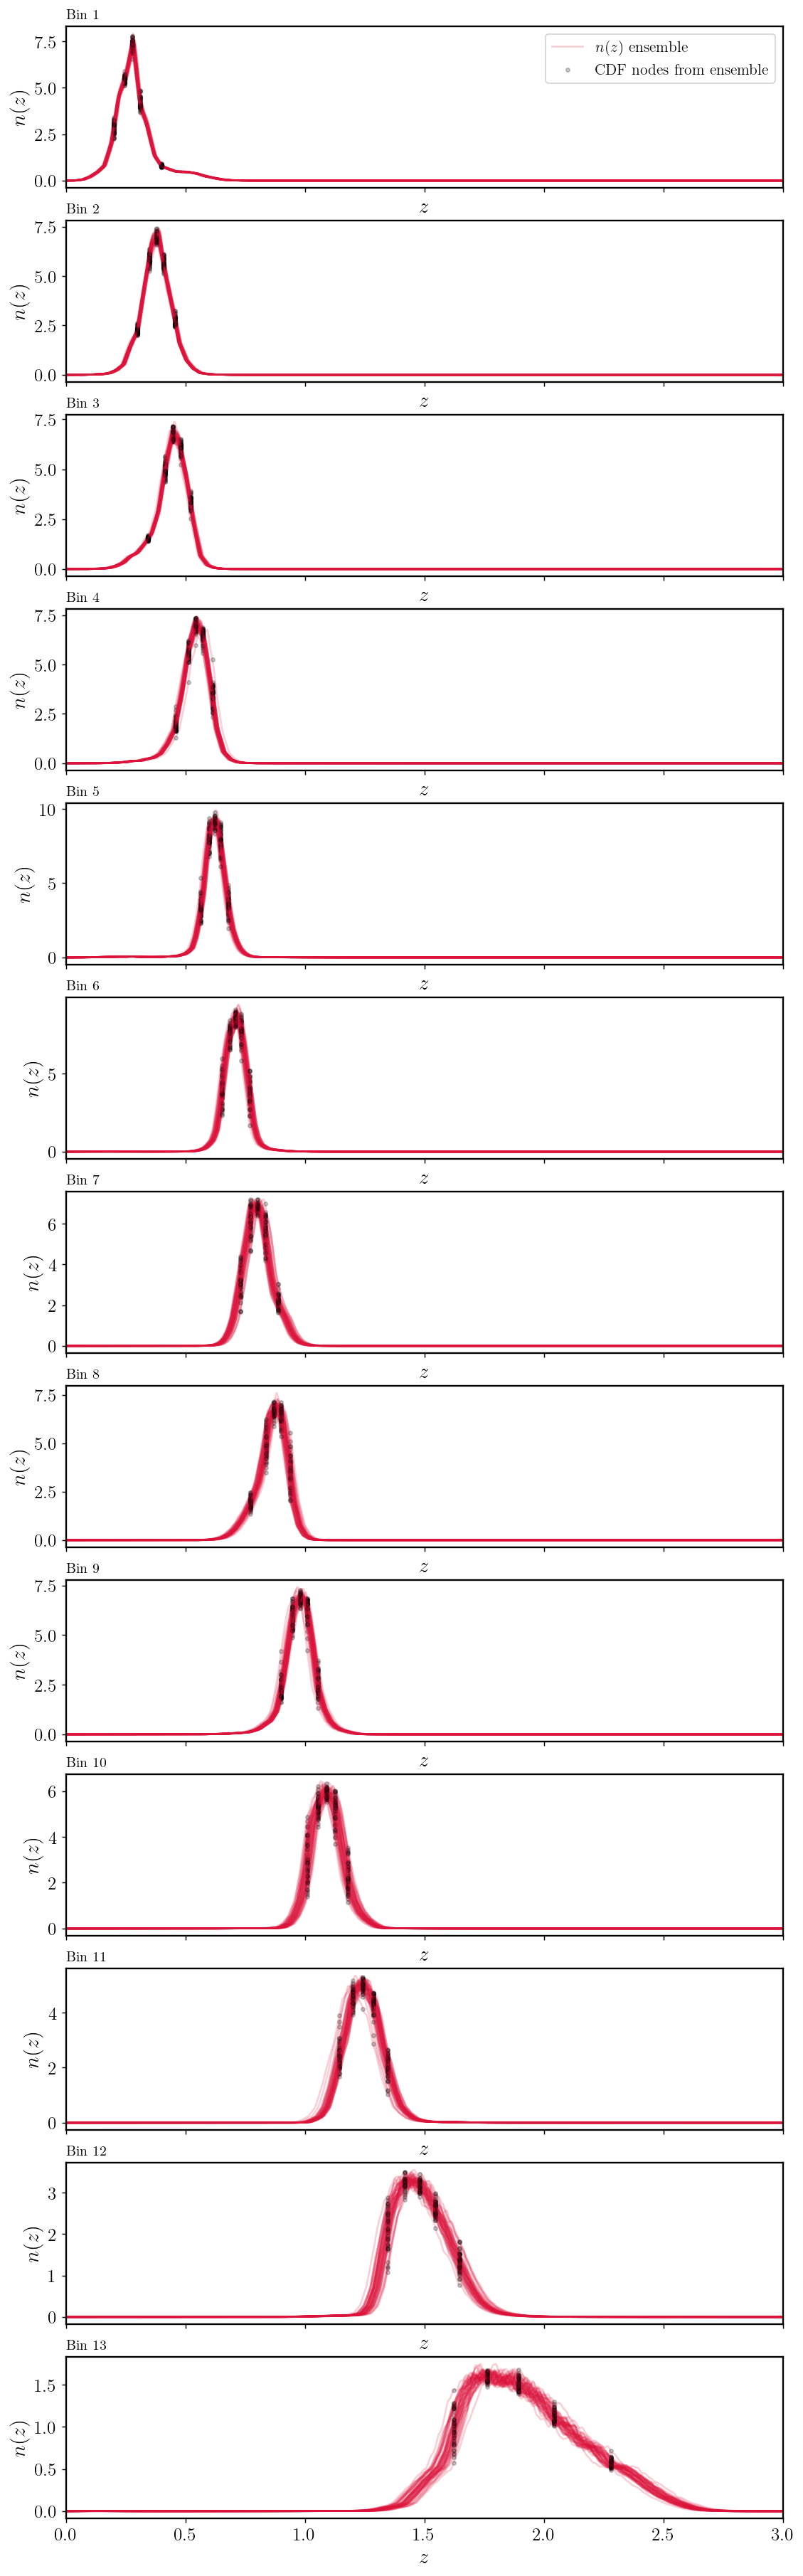

In [138]:
# Plotting training data for each bin

z_grid = z_ens_list[b]
nz_ens = nz_ensemble_list[b]

fig, axes = plt.subplots(13, 1, figsize=(10,35), sharex=True)
axes = axes.flatten()
for i in range(len(nz_ensemble_list)):
    nz_ens = nz_ensemble_list[i]
    for j, nz in enumerate(nz_ens):
        if i == 0 and j == 0:
            axes[i].plot(z_grid, nz / np.trapezoid(nz, z_grid), color='crimson', alpha=0.2, label='$n(z)$ ensemble')
            axes[i].scatter(x_nodes_list[i], Y_nodes_list[i][j], marker='.', color='black', alpha=0.2, zorder=2, label='CDF nodes from ensemble')
        else:
            axes[i].plot(z_grid, nz / np.trapezoid(nz, z_grid), color='crimson', alpha=0.2)
            axes[i].scatter(x_nodes_list[i], Y_nodes_list[i][j], marker='.', color='black', alpha=0.2, zorder=2)
        
    axes[i].set_xlim(0, 3)
    axes[i].set_title(f"Bin {i+1}", loc="left", fontsize=11)
    axes[i].set_xlabel("$z$")
    axes[i].set_ylabel("$n(z)$")
axes[0].legend()


In [117]:
# normalizing flow = invertible neural network that learns a probability distribution

import torch
from nflows.flows import Flow
from nflows.distributions import StandardNormal
from nflows.transforms import CompositeTransform, MaskedAffineAutoregressiveTransform
eps = 1e-6
U = np.log(np.clip(Y_nodes, eps, None))

mean = U.mean(axis=0)
std = U.std(axis=0) + 1e-6
U_norm = (U - mean) / std

M = U_norm.shape[1]
base = StandardNormal(shape=[M])
# all flows begin as standard Gaussian vectors, there is one flow to capture the behavior of the entire distribution 
transforms = [] # here, invertible transformations will be stored
for _ in range(5):  # 5 autoregressive layers
    transforms.append( # this is where the flow happens, each output dimension is modelled as a function of previous dimensions
        MaskedAffineAutoregressiveTransform(
            features=M,
            hidden_features=64 # small neural network inside each layer 
        )
    ) # here, each layer learns a transformation

transform = CompositeTransform(transforms) # we change the 5 layers into a single transformation
flow = Flow(transform, base) # we now start with a Gaussian base and apply the transformation to get log_prob(y)

optimizer = torch.optim.Adam(flow.parameters(), lr=1e-3) # optimize flow with Adam
data = torch.tensor(U_norm, dtype=torch.float32) 

for step in range(3000):
    idx = torch.randint(0, data.shape[0], (128,)) # randomly selects 128 indices (minibatch)
    batch = data[idx] 
    loss = -flow.log_prob(batch).mean() # negative log likelihood is computed
    optimizer.zero_grad()
    loss.backward()
    optimizer.step() # flow parameters are updated according to negative log likelihood
    print(f"Step {step}")

# In summary, the flow is a neural network that has some parameters that need to be optimized according to the data
# We define the architecture of the neural network beforehand, here we have 5 layers 


Step 0
Step 1
Step 2
Step 3
Step 4
Step 5
Step 6
Step 7
Step 8
Step 9
Step 10
Step 11
Step 12
Step 13
Step 14
Step 15
Step 16
Step 17
Step 18
Step 19
Step 20
Step 21
Step 22
Step 23
Step 24
Step 25
Step 26
Step 27
Step 28
Step 29
Step 30
Step 31
Step 32
Step 33
Step 34
Step 35
Step 36
Step 37
Step 38
Step 39
Step 40
Step 41
Step 42
Step 43
Step 44
Step 45
Step 46
Step 47
Step 48
Step 49
Step 50
Step 51
Step 52
Step 53
Step 54
Step 55
Step 56
Step 57
Step 58
Step 59
Step 60
Step 61
Step 62
Step 63
Step 64
Step 65
Step 66
Step 67
Step 68
Step 69
Step 70
Step 71
Step 72
Step 73
Step 74
Step 75
Step 76
Step 77
Step 78
Step 79
Step 80
Step 81
Step 82
Step 83
Step 84
Step 85
Step 86
Step 87
Step 88
Step 89
Step 90
Step 91
Step 92
Step 93
Step 94
Step 95
Step 96
Step 97
Step 98
Step 99
Step 100
Step 101
Step 102
Step 103
Step 104
Step 105
Step 106
Step 107
Step 108
Step 109
Step 110
Step 111
Step 112
Step 113
Step 114
Step 115
Step 116
Step 117
Step 118
Step 119
Step 120
Step 121
Step 122
Ste

In [141]:
# Defining a function that trains the normalizing flow on the training data 
from tqdm import tqdm

def normalizing_flow_per_bin(Y_nodes, n_layers=5, hidden_features=64, lr=1e-3, steps=3000):
    # normalizing flow = invertible neural network that learns a probability distribution
    eps = 1e-6
    U = np.log(np.clip(Y_nodes, eps, None))

    # standardize the log-values
    mean = U.mean(axis=0)
    std = U.std(axis=0) + 1e-6
    U_norm = (U - mean) / std

    M = U_norm.shape[1]
    base = StandardNormal(shape=[M])  # all flows begin as standard Gaussian vectors

    transforms = []  # here, invertible transformations will be stored
    for _ in range(n_layers):  # autoregressive layers
        transforms.append(
            MaskedAffineAutoregressiveTransform(
                features=M,
                hidden_features=hidden_features  # small neural network inside each layer
            )
        )  # here, each layer learns a transformation

    transform = CompositeTransform(transforms)  # combine layers into a single transformation
    flow = Flow(transform, base)  # start with Gaussian base and apply transformation to get log_prob(y)

    optimizer = torch.optim.Adam(flow.parameters(), lr=lr)  # optimize flow with Adam
    data = torch.tensor(U_norm, dtype=torch.float32)

    # training loop
    for step in tqdm(range(steps), desc="Training flow", ncols=80):
        idx = torch.randint(0, data.shape[0], (128,))  # randomly selects 128 indices (minibatch)
        batch = data[idx]
        loss = -flow.log_prob(batch).mean()  # negative log likelihood is computed
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()  # flow parameters are updated according to negative log likelihood
    
    return flow, mean, std

In [143]:
flows = []
means = []
stds = []

for b in range(len(Y_nodes_list)):
    print(f"Training flow for bin {b+1}")
    flow_b, mean_b, std_b = normalizing_flow_per_bin(Y_nodes_list[b])
    flows.append(flow_b)
    means.append(mean_b)
    stds.append(std_b)


--- Training flow for bin 1 ---


Training flow:   0%|                                   | 0/3000 [00:00<?, ?it/s]

Training flow: 100%|███████████████████████| 3000/3000 [00:18<00:00, 160.88it/s]



--- Training flow for bin 2 ---


Training flow: 100%|███████████████████████| 3000/3000 [00:17<00:00, 169.54it/s]


...

Training flow: 100%|███████████████████████| 3000/3000 [00:18<00:00, 158.51it/s]



--- Training flow for bin 12 ---


Training flow: 100%|███████████████████████| 3000/3000 [00:19<00:00, 157.29it/s]



--- Training flow for bin 13 ---


Training flow: 100%|███████████████████████| 3000/3000 [00:20<00:00, 148.51it/s]


In [163]:
def plot_all_bins(flows, means, stds, x_nodes_list, Y_nodes_list,
                  nz_ensemble_list, z_ens_list,
                  z_pred, reconstruct_nz_from_nodes_gp_square):
    fig, axes = plt.subplots(len(flows), 2, figsize=(22, 4*len(flows)))
    for b in range(len(flows)):
        flow = flows[b]
        mean = means[b]
        std = stds[b]
        x_nodes = x_nodes_list[b]
        Y_nodes = Y_nodes_list[b]
        nz_ens = nz_ensemble_list[b]
        z_grid = z_ens_list[b]

        ax_left = axes[b, 0]
        ax_right = axes[b, 1]
        U_flow_norm = flow.sample(50).detach().numpy()
        U_flow = U_flow_norm * std + mean
        Y_flow = np.exp(U_flow)

        for y in Y_flow:
            y_pred = reconstruct_nz_from_nodes_gp_square(
                z_pred,
                x_nodes,
                y,
                z_bounds=(0.0, 3.0),
                corr_len=0.03,
                amp=0.04,
                alpha=0.0,  # <-- set 0 for interpolation
                kernel_class=RBF,
                nu=1.5,
                return_std=False,
            )
            ax_left.plot(z_pred, y_pred, color="crimson", alpha=0.2)
        for i, nodes in enumerate(Y_nodes):
            if i == 0:
                ax_left.scatter(x_nodes, nodes, color='gray', marker='.', alpha=0.2, label='Training nodes')
            else:
                ax_left.scatter(x_nodes, nodes, color='gray', marker='.', alpha=0.2)

        if min(x_nodes)-0.5 < 0:
            ax_left.set_xlim(0, max(x_nodes)+0.5)
        else:
            ax_left.set_xlim(min(x_nodes)-0.5, max(x_nodes)+0.5)
        ax_left.set_title(f"Bin {b+1}: Normalizing Flow Prior Samples")
        ax_left.set_xlabel("$z$")
        ax_left.set_ylabel("$n(z)$")
        ax_left.set_ylim(0, Y_nodes.max()+1)
        ax_left.legend()
        for i in range(nz_ens.shape[0]):
            ax_right.plot(
                z_grid,
                nz_ens[i] / np.trapezoid(nz_ens[i], z_grid),
                color="crimson", alpha=0.2, lw=0.8
            )
        for i, nodes in enumerate(Y_nodes):
            if i == 0:
                ax_right.scatter(x_nodes, nodes, color='gray', marker='.', alpha=0.2)
            else:
                ax_right.scatter(x_nodes, nodes, color='gray', marker='.', alpha=0.2)
        if min(x_nodes)-0.5 < 0:
            ax_right.set_xlim(0, max(x_nodes)+0.5)
        else:
            ax_right.set_xlim(min(x_nodes)-0.5, max(x_nodes)+0.5)
        ax_right.set_title(f"Bin {b+1}: Ensemble Curves")
        ax_right.set_xlabel("$z$")
        ax_right.set_ylabel("$n(z)$")
        ax_right.set_ylim(0, Y_nodes.max()+1)

    plt.tight_layout()
    return fig

In [156]:
print(x_nodes_list[1])

[0.29685385 0.34654416 0.37693726 0.40749366 0.45550902]


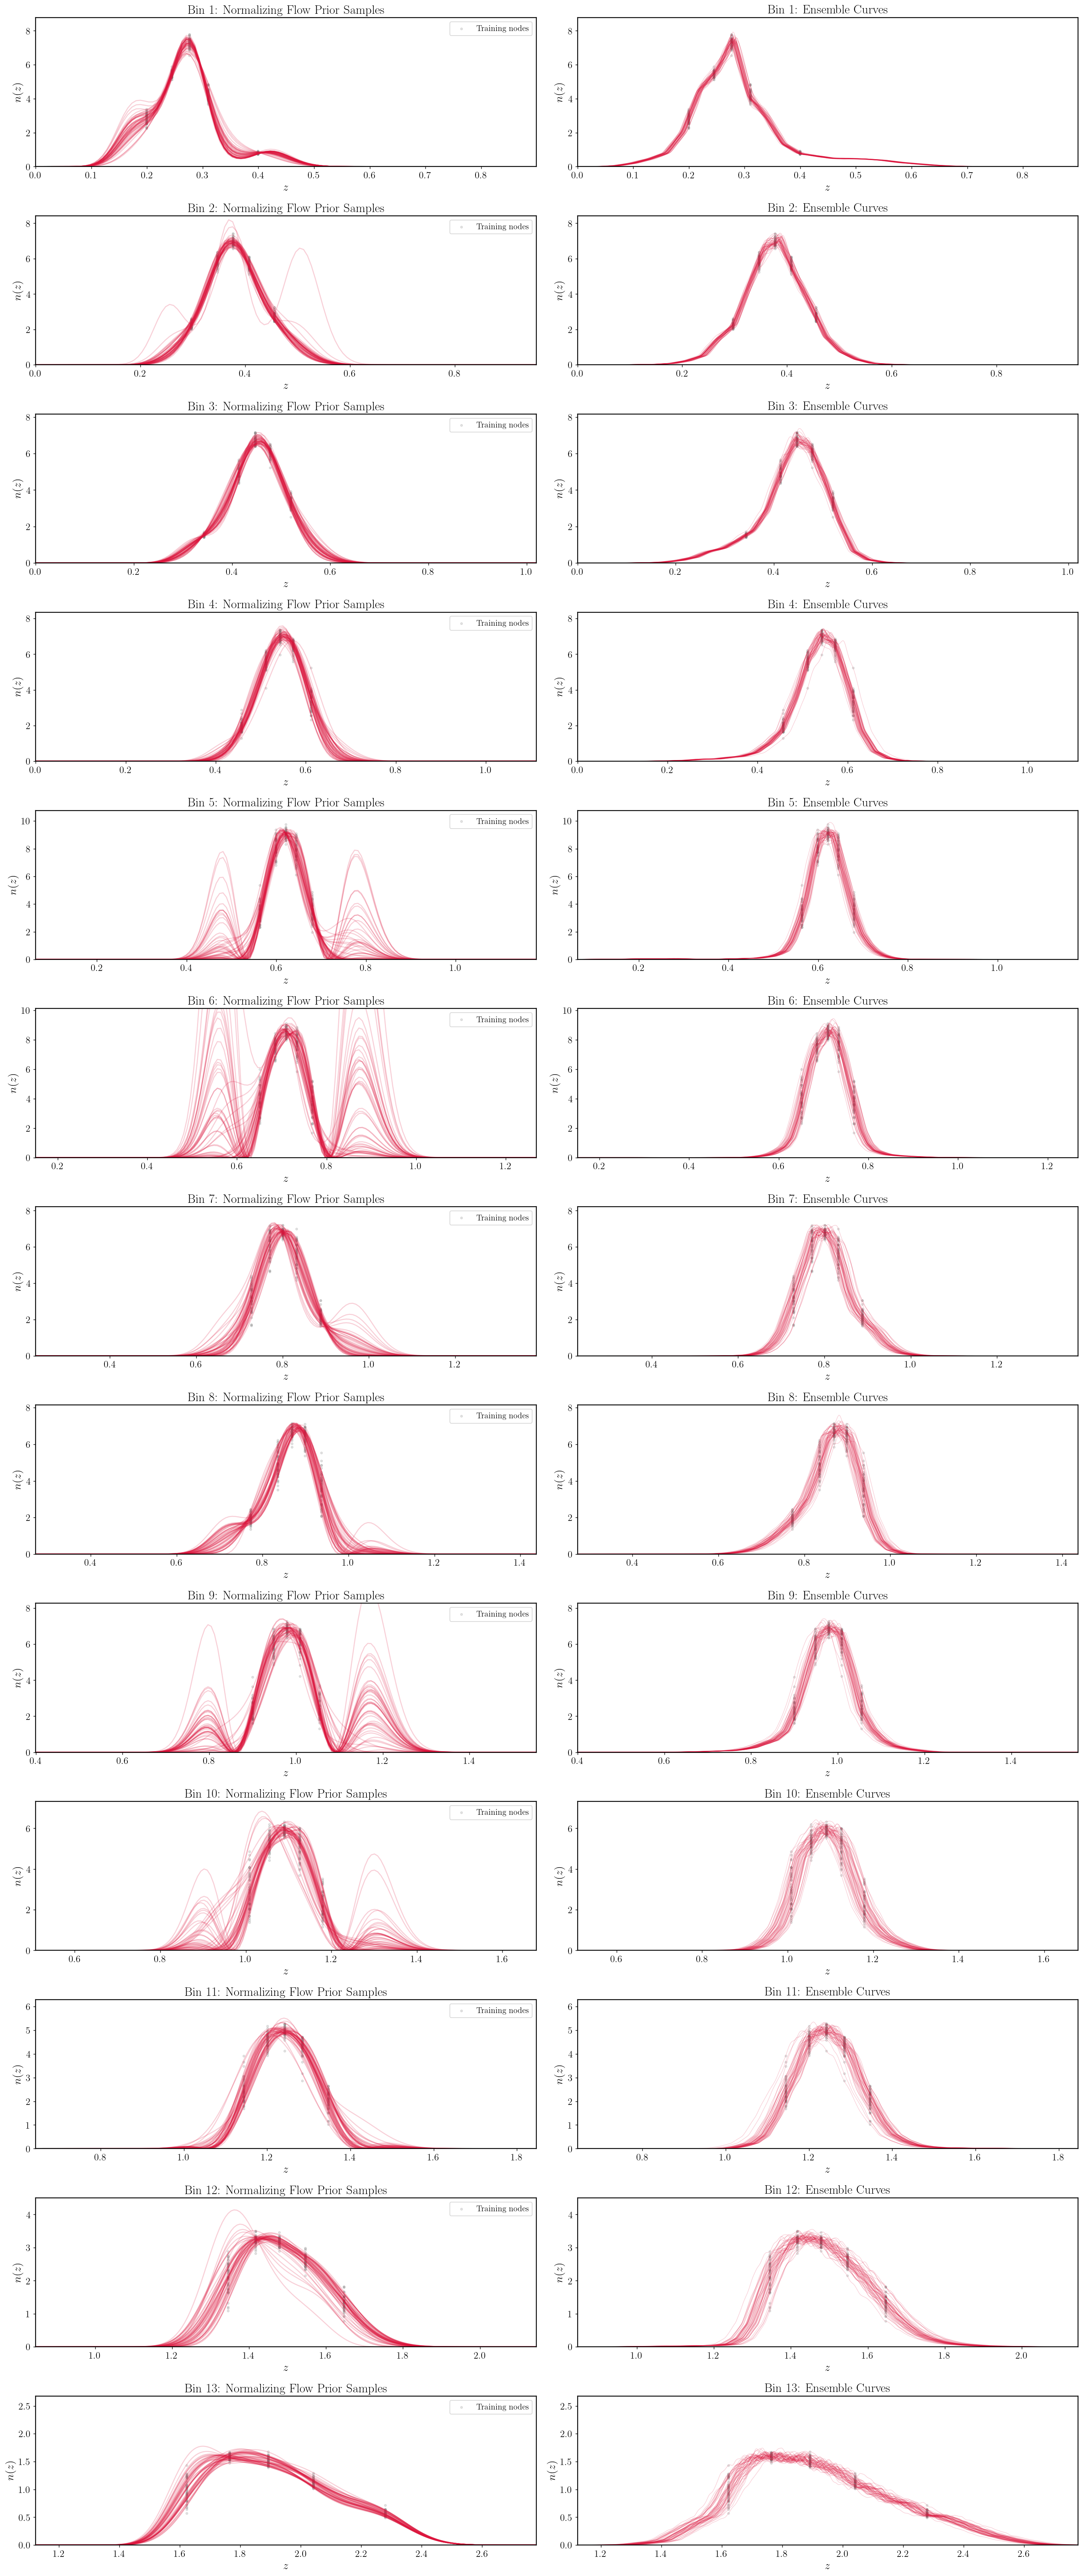

In [164]:
fig = plot_all_bins(
    flows, means, stds,
    x_nodes_list, Y_nodes_list,
    nz_ensemble_list, z_ens_list,
    z_pred, reconstruct_nz_from_nodes_gp_square
)